# 03 · Baseline Models, Evaluation and Initial Findings (Milestone 3)

**Project:** An early-warning system for essential-price shocks across income quintiles in Pakistan (DS4SG, CS/SDP 312/314)

**The question.** Standing at the end of week *t*, can we tell whether week *t+1* will be a **price-shock week**
(the group's SPI rises by at least 1%) for each consumption quintile? This is hypothesis **H1** from Milestone 2. A
working early warning would let BISP time a top-up *before* a shock reaches the poorest households instead of after.

**What a baseline is for.** Before the advanced models of Milestone 4, we need honest reference points: how well do
simple, well-understood models do, when measured in a way that cannot cheat by looking at the future?

| Rubric item (M3) | Section |
|---|---|
| A. Naive benchmark; at least two ML models; justification | §3, §4 |
| B. Split ratio and stratification; leakage-free cross-validation; hyperparameter tuning | §1, §2, §4, §5 |
| C. Accuracy, precision, recall, specificity, F1, ROC-AUC; FP vs FN costs; confusion matrices; edge cases | §6, §7, §8 |
| D. Feature importance; policy takeaways; roadmap for M4 | §9, §11 |
| Formal test of H1 (promised in the M2 manuscript) | §10 |

**Inputs:** `data/processed/master_features.csv` (from notebook 01 and `src/features/build_features.py`) and
`data/processed/items_weekly_panel.csv` (only for the edge-case analysis).
**Shared code:** `src/models/baseline.py` holds every modelling function. The script
`src/models/train_baselines.py` runs the same steps from the command line and gives identical numbers.
**Outputs:** figures `reports/figures/figB1`–`figB8`, tables `reports/tables/m3_*.csv`, fitted models in `models/m3_baselines/`.

In [1]:
# Setup
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score
from sklearn.tree import plot_tree, export_text
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / "requirements.txt").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from utils.plot_style import apply_style, GROUP_COLORS, SERIES, INK, INK_SECONDARY, GRID
from models import baseline as B                 # all modelling code: data, folds, models, metrics
from features.build_features import component    # maps an SPI item to its price component

apply_style()
warnings.filterwarnings("ignore", category=UserWarning)   # sklearn feature-name notices only
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)
np.random.seed(B.SEED)

FIG_DIR, TABLE_DIR = ROOT / "reports" / "figures", ROOT / "reports" / "tables"
MODELS = ["Logistic regression", "KNN", "Decision tree"]
BENCH = ["Majority class", "Persistence"]
COLORS = {"Logistic regression": SERIES[0], "KNN": SERIES[1], "Decision tree": SERIES[2],
          "Persistence": SERIES[6], "Majority class": "#9a9893"}


def caption(fig, text, y=-0.02):
    # Figure caption under the plot, in secondary ink (never the series colour).
    fig.text(0.01, y, text, ha="left", va="top", fontsize=9, color=INK_SECONDARY)


def pct(x, d=1):
    return f"{100 * x:.{d}f}%"

## 1. The modelling dataset and the train/test split (rubric B: data partitioning)

**Rows.** One row = one SPI week × one quintile group (Q1 … Q5). The Combined index is left out: it is a
weighted average of the five quintiles, so including it would add the same week's information a sixth time.

**Features (18), all known at the end of week *t*** (the M2 feature design):

| Block | Columns | Why it is there |
|---|---|---|
| Own history | `spi_wow_pct`, `spi_chg_4w` | does this group's recent inflation carry forward? |
| Lead signals (H1) | `fx_chg_8w`, `shocks_last_4w`, `momentum_spikes_4w`, `infl_staples_4w`, `fuel_review_next_week`, `fy_start_next_week` | the early-warning signals of M2 §III-E |
| Component momentum | `infl_perishables_4w`, `infl_utilities_4w`, `infl_motor_fuel_4w` | the volatile components behind most weekly variance (M2 §III-D) |
| Controls | `policy_rate`, `ramadan_next_week`, `pre_eid_adha_4w`, `grp_Q1` … `grp_Q4` (Q5 = reference) | monetary stance, calendar, level differences between groups |

**Split.** Chronological, and fixed in M2 before any model was fitted: **train = weeks up to
31 December 2024, test = 2025 onward.** Rows with a missing feature or target are dropped (listwise deletion):
the first 8 weeks, before an 8-week exchange-rate change exists, and the last week, whose next week is not yet known.

In [2]:
df = B.load_model_data()
train, test = B.split_train_test(df)
X, y = train[B.FEATURES], train[B.TARGET]          # training period: features and target
Xt, yt = test[B.FEATURES], test[B.TARGET]          # test period: touched only in Section 6 onward

n_tr, n_te = train["week_end"].nunique(), test["week_end"].nunique()
print(f"Rows dropped (listwise deletion): {df.attrs['rows_dropped']} = {df.attrs['rows_dropped'] // 5} weeks x 5 groups")
print(f"Train: {train['week_end'].min():%d %b %Y} to {train['week_end'].max():%d %b %Y}: {n_tr} weeks, {len(train):,} rows")
print(f"Test:  {test['week_end'].min():%d %b %Y} to {test['week_end'].max():%d %b %Y}: {n_te} weeks, {len(test):,} rows")
print(f"Split ratio by weeks: {n_tr / (n_tr + n_te):.1%} train / {n_te / (n_tr + n_te):.1%} test")
print(f"Features: {len(B.FEATURES)} ({len(B.CONTINUOUS)} continuous, {len(B.BINARY)} binary)")

# Class balance by split and group: how rare are shock weeks?
bal = df.groupby(["group", "split"])[B.TARGET].agg(["sum", "mean"]).unstack("split")
bal.columns = [f"{s} {'shock rows' if m == 'sum' else 'shock rate %'}" for m, s in bal.columns]
tot = df.groupby("split")[B.TARGET].agg(["sum", "mean"])
bal.loc["All Q1-Q5"] = [tot.loc["test", "sum"], tot.loc["train", "sum"], tot.loc["test", "mean"], tot.loc["train", "mean"]]
bal = bal[["train shock rows", "train shock rate %", "test shock rows", "test shock rate %"]]
bal[["train shock rate %", "test shock rate %"]] *= 100
display(bal.round(1))
bal.to_csv(TABLE_DIR / "m3_class_balance.csv")

shock_weeks_test = test.loc[yt == 1, "week_end"].nunique()
print(f"Distinct test weeks with a shock in at least one group: {shock_weeks_test} of {n_te}")

Rows dropped (listwise deletion): 45 = 9 weeks x 5 groups
Train: 31 Oct 2019 to 26 Dec 2024: 270 weeks, 1,350 rows
Test:  02 Jan 2025 to 24 Sep 2026: 91 weeks, 455 rows
Split ratio by weeks: 74.8% train / 25.2% test
Features: 18 (10 continuous, 8 binary)


,train shock rows,train shock rate %,test shock rows,test shock rate %
group,,,,
Q1,44.0,16.3,7.0,7.7
Q2,51.0,18.9,9.0,9.9
Q3,46.0,17.0,6.0,6.6
Q4,50.0,18.5,7.0,7.7
Q5,41.0,15.2,6.0,6.6
All Q1-Q5,232.0,17.2,35.0,7.7


Distinct test weeks with a shock in at least one group: 13 of 91


**Reading the split**
* The split is about **75 / 25 by weeks**. It is set by the calendar (all of 2025–26 is the test period), not by a
  random draw, so every test week is later than every training week, as it would be for a real forecaster.
* **Classes are imbalanced:** about 17% of training rows are followed by a shock, against about 8% of test rows.
  The rubric asks for stratified sampling when classes are imbalanced. A stratified split draws rows *at random* so
  that both parts have the same shock rate, and that would break the time order twice over: the model would learn from
  2025 to predict 2022, and the five quintile rows of one week (which share the same week-level signals) would be split
  between training and test. We therefore keep the time order and deal with the imbalance in three other ways:
  class weights as a tuning option, a cost-based alarm threshold, and metrics that do not reward
  always saying "no shock" (recall, specificity, F1, ROC-AUC, PR-AUC). §5 shows what shuffled stratified K-fold
  would have reported instead.
* **The test period is calmer than the training period.** Inflation fell sharply in 2025, so the shock rate halved.
  That is a genuine change in the world, not a sampling accident. It makes the test harder for an
  alarm system, because with fewer real shocks any alarm is more likely to be false.
* The test has few independent shock events, so test metrics are noisy; §6 attaches bootstrap intervals.

## 2. Validation framework: expanding-window cross-validation (rubric B)

Ordinary K-fold cross-validation shuffles rows into K random groups. That is fine for independent observations, but
our rows are a **time series**, and it would let the model train on the future and be validated on the past. We
use **forward-chaining (expanding-window) cross-validation** instead:

* **K = 4 folds, one validation year each (2021, 2022, 2023, 2024).** Fold *k* trains on *every* week before
  1 January of its validation year, so the training window grows fold by fold, like a forecaster who keeps adding
  history.
* **Calendar years, not equal-sized blocks,** so that every validation block contains exactly one fiscal-year start,
  one Ramadan and one Eid ul-Adha. Equal blocks of about 45 weeks would contain zero or two of some of these events.
* **Whole weeks move together.** The five quintile rows of a week share every week-level feature (exchange rate,
  calendar, component inflation), so they are never split between training and validation.
* **No gap is needed** between training and validation: the target is one week ahead, so the last training label
  (the shock in the first validation week) is already known by the time that week's forecast is made.
* The test period (2025–26) is **not used at all** until Section 6.

In [3]:
folds = B.time_series_folds(train)
ft = B.fold_table(train, folds)
display(ft.round(1))
ft.to_csv(TABLE_DIR / "m3_cv_folds.csv", index=False)

# Sanity checks: validation weeks are always later than training weeks, and no week is split.
for tr, va in folds:
    assert train["week_end"].iloc[tr].max() < train["week_end"].iloc[va].min()
    assert not set(train["week_end"].iloc[tr]) & set(train["week_end"].iloc[va])
print("Every fold: all training weeks precede all validation weeks; no week appears on both sides.")

,fold,train weeks,n train weeks,validation weeks,n validation weeks,train shock rate %,validation shock rate %,validation shocks (rows)
0,1,31 Oct 2019 – 31 Dec 2020,62,07 Jan 2021 – 30 Dec 2021,52,9.4,13.1,34
1,2,31 Oct 2019 – 30 Dec 2021,114,06 Jan 2022 – 29 Dec 2022,52,11.1,33.1,86
2,3,31 Oct 2019 – 29 Dec 2022,166,05 Jan 2023 – 28 Dec 2023,52,18.0,20.0,52
3,4,31 Oct 2019 – 28 Dec 2023,218,04 Jan 2024 – 26 Dec 2024,52,18.4,11.9,31


Every fold: all training weeks precede all validation weeks; no week appears on both sides.


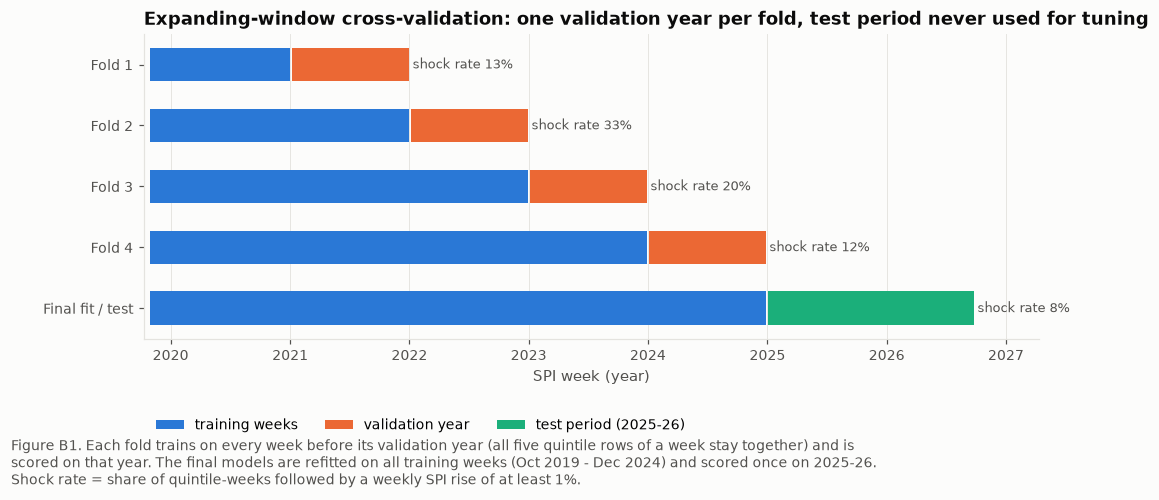

In [4]:
# Figure B1: the cross-validation design
fig, ax = plt.subplots(figsize=(10.5, 3.6))
t0, t_end = train["week_end"].min(), test["week_end"].max()
C_TR, C_VA, C_TE = SERIES[0], SERIES[1], SERIES[2]
rows = [(f"Fold {k + 1}", train["week_end"].iloc[tr].min(), train["week_end"].iloc[tr].max(),
         train["week_end"].iloc[va].min(), train["week_end"].iloc[va].max()) for k, (tr, va) in enumerate(folds)]
for i, (lab, a, b, c, d) in enumerate(rows):
    yy = len(rows) - i
    ax.barh(yy, (b - a).days, left=a, color=C_TR, height=0.55)
    ax.barh(yy, (d - c).days, left=c, color=C_VA, height=0.55)
    ax.text(d + pd.Timedelta(days=12), yy, f"shock rate {ft.loc[i, 'validation shock rate %']:.0f}%", va="center",
            fontsize=8.5, color=INK_SECONDARY)
ax.barh(0, (train["week_end"].max() - t0).days, left=t0, color=C_TR, height=0.55)
ax.barh(0, (t_end - test["week_end"].min()).days, left=test["week_end"].min(), color=C_TE, height=0.55)
ax.text(t_end + pd.Timedelta(days=12), 0, f"shock rate {100 * yt.mean():.0f}%", va="center", fontsize=8.5,
        color=INK_SECONDARY)
ax.set_yticks(range(len(rows) + 1), ["Final fit / test"] + [r[0] for r in rows][::-1])
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_xlim(t0 - pd.Timedelta(days=20), t_end + pd.Timedelta(days=200))
ax.grid(axis="y", visible=False)
ax.set_xlabel("SPI week (year)")
ax.set_title("Expanding-window cross-validation: one validation year per fold, test period never used for tuning")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=C_TR, label="training weeks"), Patch(color=C_VA, label="validation year"),
                   Patch(color=C_TE, label="test period (2025-26)")], loc="upper left", ncol=3,
          bbox_to_anchor=(0, -0.22))
caption(fig, "Figure B1. Each fold trains on every week before its validation year (all five quintile rows of a week stay together) and is\n"
             "scored on that year. The final models are refitted on all training weeks (Oct 2019 - Dec 2024) and scored once on 2025-26.\n"
             "Shock rate = share of quintile-weeks followed by a weekly SPI rise of at least 1%.", y=-0.14)
fig.savefig(FIG_DIR / "figB1_cv_design.png")
plt.show()

**Leakage checklist.** Data leakage means information that would not be available at forecast time reaches the model.

| Possible leak | How it is closed |
|---|---|
| Training on later weeks than the ones predicted | expanding window: validation is always later than training (asserted above) |
| Sister quintile rows of the same week on both sides | folds are built from whole weeks |
| Scaling with statistics from validation or test data | scalers sit *inside* each model's `Pipeline`, so they are re-fitted on each fold's training part. The M2 `*_z` / `*_mm` columns (scaled on all of 2019–24) are deliberately not used |
| Features that peek at week *t+1* | every feature is known at the end of week *t* or is a calendar fact (the M2 feature design) |
| Choosing the alarm threshold on the test data | thresholds are chosen on out-of-fold predictions for 2021–24 (§6) |
| Tuning on the test data | hyperparameters are chosen on the four validation years only |

One small, disclosed exception: the seven "momentum" items behind `momentum_spikes_4w` were chosen in M2 using all
training weeks up to 2024. Inside cross-validation, that choice has therefore seen the later folds. It never sees the
test period.

## 3. Naive benchmarks (rubric A)

Any model must beat two heuristics that need no learning at all:

* **Majority class** (`DummyClassifier(strategy="prior")`). It always predicts "no shock". Its predicted probability
  is the training shock rate, the same for every row, so its ROC-AUC is exactly 0.5. It sets the accuracy floor, and it
  shows why accuracy misleads here: with about 83% calm weeks it is right 83% of the time while catching no shock.
* **Persistence** ("next week will be like this week"). It predicts a shock next week if this week was a shock week.
  It is the standard naive forecast in time series, and a fair test of whether shocks cluster.

In [5]:
benchmarks = B.make_benchmarks()
oof, fitted = {}, {}
for name, b in benchmarks.items():
    fitted[name] = b.fit(X, y)
    oof[name] = B.oof_predict(b, X, y, folds)

val = ~np.isnan(oof["Persistence"])            # rows of the four validation years
for name in BENCH:
    pooled = roc_auc_score(y[val], oof[name][val])
    per_fold = [roc_auc_score(y.iloc[va], oof[name][va]) for _, va in folds]
    print(f"{name:15s} pooled CV AUC {pooled:.3f}; by fold {np.round(per_fold, 3)}")
print(f"Majority-class accuracy on the validation years: {1 - y[val].mean():.1%} (it never raises an alarm)")

Majority class  pooled CV AUC 0.467; by fold [0.5 0.5 0.5 0.5]
Persistence     pooled CV AUC 0.584; by fold [0.577 0.586 0.498 0.615]
Majority-class accuracy on the validation years: 80.5% (it never raises an alarm)


## 4. Baseline models: justification and systematic tuning (rubric A and B)

| | Logistic regression | k-nearest neighbours (KNN) | Decision tree (shallow) |
|---|---|---|---|
| **How it works** | adds up weighted features into a log-odds score, then maps it to a probability | finds the *k* past weeks most similar to this one (Euclidean distance, Unit 11) and reports the share that were followed by a shock | asks a short sequence of yes/no questions ("did the rupee fall by more than 2%?") and reports the shock rate in the final group; each question is the split that most reduces Gini impurity (Unit 08) |
| **Why it suits this problem** | the model form of H1, so its coefficients and odds ratios test the hypothesis directly; produces probabilities a policy desk can act on; regularisation suits a small sample (270 weeks) | an "analogue forecast": "the last times prices looked like this, what happened next?". Makes no assumption about the shape of the relationship | turns into if-then alarm rules that a non-technical official can read and audit; captures thresholds and interactions (e.g. fiscal-year start *and* a falling rupee) |
| **Main weakness** | assumes each feature shifts the log-odds by a fixed amount (linear, no interactions) | sensitive to feature scales and to irrelevant features (distance is spread over all 18; both are KNN limitations in Unit 11); no feature weights to interpret | unstable: a small change in data can change the splits (high variance), so depth must be limited |
| **Tuned hyperparameters** | `C` (inverse penalty strength), penalty type (`l1_ratio` 0 = L2 ridge, 1 = L1 lasso), class weights | `k`, neighbour weighting (uniform vs distance), scaler for continuous features (z-score vs Min-Max) | `max_depth`, `min_samples_leaf`, class weights |
| **Scaling** | z-score on all features (so the penalty treats them alike) | continuous features scaled; 0/1 flags left as 0/1 | none needed |

**Tuning procedure.** Every combination in each grid (an exhaustive *grid search*) is trained on each
fold's training weeks and predicts that fold's validation year. Each setting gets two scores:
* **Pooled CV AUC**: one ROC-AUC over the out-of-fold predictions of all four validation years stacked together. This
  is the **selection criterion**. The early-warning system will use *one* alarm threshold in every year, so a
  probability of 0.3 has to mean the same thing in 2022 as in 2024. A setting that ranks weeks well inside each year
  but whose probability level drifts from year to year scores well fold by fold, and badly when pooled.
* **Mean ± SD of the four per-fold AUCs**: the usual K-fold summary and its fold-to-fold variance.

The best setting is then refitted on all 270 training weeks.

In [6]:
models, grids = B.make_models()
for name in MODELS:
    n = int(np.prod([len(v) for v in grids[name].values()]))
    print(f"{name}: {n} settings x {len(folds)} folds = {n * len(folds)} fits")
    for k, v in grids[name].items():
        print(f"    {k.split('__')[-1]:18s} {[type(x).__name__ if hasattr(x, 'fit') else x for x in v]}")

Logistic regression: 48 settings x 4 folds = 192 fits
    C                  [0.0001, 0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10, 100]
    l1_ratio           [0.0, 1.0]
    class_weight       [None, 'balanced']
KNN: 44 settings x 4 folds = 176 fits
    n_neighbors        [5, 10, 15, 25, 35, 50, 75, 100, 150, 200, 250]
    weights            ['uniform', 'distance']
    cont               ['StandardScaler', 'MinMaxScaler']
Decision tree: 98 settings x 4 folds = 392 fits
    max_depth          [1, 2, 3, 4, 5, 6, 8]
    min_samples_leaf   [5, 10, 20, 40, 80, 120, 160]
    class_weight       [None, 'balanced']


In [7]:
grid_res = {}
for name in MODELS:
    res, best, oof[name] = B.grid_search_time_cv(models[name], grids[name], X, y, folds)
    fitted[name], grid_res[name] = best, res
    res.drop(columns="_params").to_csv(TABLE_DIR / f"m3_cv_grid_{name.lower().replace(' ', '_')}.csv", index=False)
    print(f"\n{name}: top 5 of {len(res)} settings (sorted by pooled CV AUC)")
    display(res.drop(columns=["_params", "selected"]).head(5).round(3))


Logistic regression: top 5 of 48 settings (sorted by pooled CV AUC)


,C,class_weight,l1_ratio,pooled CV AUC,mean fold AUC,fold AUC SD,AUC 1,AUC 2,AUC 3,AUC 4,train AUC
0,0.000,balanced,0.0,0.643,0.651,0.053,0.736,0.634,0.644,0.590,0.790
1,0.000,balanced,0.0,0.642,0.649,0.056,0.735,0.634,0.647,0.581,0.794
2,0.001,balanced,0.0,0.639,0.642,0.070,0.736,0.638,0.656,0.539,0.804
3,0.003,balanced,0.0,0.636,0.627,0.098,0.731,0.645,0.666,0.466,0.820
4,0.010,balanced,0.0,0.630,0.615,0.124,0.722,0.652,0.681,0.404,0.837



KNN: top 5 of 44 settings (sorted by pooled CV AUC)


,n_neighbors,weights,cont,pooled CV AUC,mean fold AUC,fold AUC SD,AUC 1,AUC 2,AUC 3,AUC 4,train AUC
0,100,uniform,StandardScaler,0.643,0.672,0.080,0.792,0.565,0.671,0.661,0.776
1,150,uniform,StandardScaler,0.640,0.669,0.085,0.806,0.575,0.658,0.636,0.759
2,100,distance,StandardScaler,0.640,0.668,0.074,0.781,0.576,0.672,0.644,1.000
3,150,distance,StandardScaler,0.640,0.668,0.080,0.800,0.587,0.655,0.630,1.000
4,200,distance,StandardScaler,0.627,0.655,0.074,0.777,0.600,0.652,0.592,1.000



Decision tree: top 5 of 98 settings (sorted by pooled CV AUC)


,class_weight,max_depth,min_samples_leaf,pooled CV AUC,mean fold AUC,fold AUC SD,AUC 1,AUC 2,AUC 3,AUC 4,train AUC
0,NaN,4,40,0.652,0.578,0.082,0.488,0.674,0.642,0.507,0.849
1,NaN,3,40,0.649,0.569,0.089,0.488,0.669,0.646,0.474,0.828
2,NaN,5,40,0.646,0.582,0.072,0.488,0.667,0.634,0.537,0.869
3,NaN,8,40,0.636,0.561,0.096,0.488,0.667,0.642,0.446,0.876
4,NaN,1,120,0.633,0.599,0.067,0.651,0.575,0.668,0.500,0.685


In [8]:
# Selected setting of each model, with the benchmarks for comparison
def cv_row(name, params=""):
    per = [roc_auc_score(y.iloc[va], oof[name][va]) for _, va in folds]
    return {"model": name, "selected setting": params, "pooled CV AUC": roc_auc_score(y[val], oof[name][val]),
            "mean fold AUC": np.mean(per), "fold AUC SD": np.std(per),
            **{f"AUC {yr}": a for yr, a in zip(B.VAL_YEARS, per)}}

summary = []
for name in MODELS:
    top = grid_res[name].iloc[0]
    params = ", ".join(f"{k}={v}" for k, v in B._short(top["_params"]).items())
    summary.append({**cv_row(name, params), "train AUC": top["train AUC"]})
summary += [cv_row(n, "no tuning") for n in BENCH]
cv_summary = pd.DataFrame(summary).set_index("model")
display(cv_summary.round(3))
cv_summary.to_csv(TABLE_DIR / "m3_cv_summary.csv")

,selected setting,pooled CV AUC,mean fold AUC,fold AUC SD,AUC 2021,AUC 2022,AUC 2023,AUC 2024,train AUC
model,,,,,,,,,
Logistic regression,"C=0.0001, class_weight=balanced, l1_ratio=0.0",0.643,0.651,0.053,0.736,0.634,0.644,0.590,0.790
KNN,"n_neighbors=100, weights=uniform, cont=Standar...",0.643,0.672,0.080,0.792,0.565,0.671,0.661,0.776
Decision tree,"class_weight=None, max_depth=4, min_samples_le...",0.652,0.578,0.082,0.488,0.674,0.642,0.507,0.849
Majority class,no tuning,0.467,0.500,0.000,0.500,0.500,0.500,0.500,NaN
Persistence,no tuning,0.584,0.569,0.044,0.577,0.586,0.498,0.615,NaN


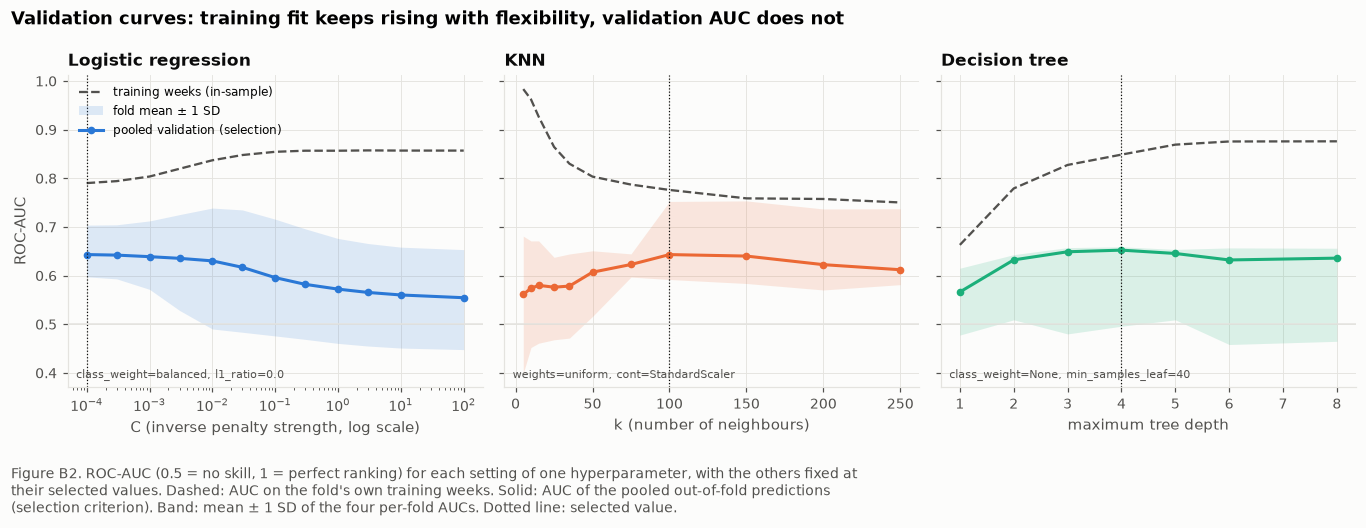

In [9]:
# Figure B2: validation curves (one hyperparameter varied, the others held at their selected values)
def curve(name, xparam, fixed):
    r = grid_res[name]
    for k, v in fixed.items():
        r = r[r[k].fillna("None").astype(str) == str(v)]   # None is stored as NaN in the table
    return r.sort_values(xparam)

sel = {n: B._short(grid_res[n].iloc[0]["_params"]) for n in MODELS}
specs = [("Logistic regression", "C", "C (inverse penalty strength, log scale)", True),
         ("KNN", "n_neighbors", "k (number of neighbours)", False),
         ("Decision tree", "max_depth", "maximum tree depth", False)]
fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.1), sharey=True)
for ax, (name, xp, xlabel, logx) in zip(axes, specs):
    c = curve(name, xp, {k: v for k, v in sel[name].items() if k != xp})
    xs = c[xp].astype(float)
    ax.plot(xs, c["train AUC"], color=INK_SECONDARY, ls="--", lw=1.5, label="training weeks (in-sample)")
    ax.fill_between(xs, c["mean fold AUC"] - c["fold AUC SD"], c["mean fold AUC"] + c["fold AUC SD"],
                    color=COLORS[name], alpha=0.15, lw=0, label="fold mean ± 1 SD")
    ax.plot(xs, c["pooled CV AUC"], color=COLORS[name], marker="o", ms=4, label="pooled validation (selection)")
    ax.axvline(float(sel[name][xp]), color=INK, lw=0.8, ls=":")
    ax.axhline(0.5, color=GRID, lw=1)
    if logx:
        ax.set_xscale("log")
    ax.set_xlabel(xlabel)
    fixed_txt = ", ".join(f"{k}={v}" for k, v in sel[name].items() if k != xp)
    ax.set_title(f"{name}", fontsize=11)
    ax.text(0.02, 0.03, fixed_txt, transform=ax.transAxes, fontsize=7.5, color=INK_SECONDARY)
axes[0].set_ylabel("ROC-AUC")
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Validation curves: training fit keeps rising with flexibility, validation AUC does not", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
fig.tight_layout()
caption(fig, "Figure B2. ROC-AUC (0.5 = no skill, 1 = perfect ranking) for each setting of one hyperparameter, with the others fixed at\n"
             "their selected values. Dashed: AUC on the fold's own training weeks. Solid: AUC of the pooled out-of-fold predictions\n"
             "(selection criterion). Band: mean ± 1 SD of the four per-fold AUCs. Dotted line: selected value.", y=-0.03)
fig.savefig(FIG_DIR / "figB2_validation_curves.png")
plt.show()

**Reading the tuning results**

* **Logistic regression** chose the strongest penalty in the grid (C = 0.0001, L2 ridge, balanced class weights), but
  the curve is flat at that end: with L2 and balanced weights, every C ≤ 0.01 gives a pooled AUC of 0.63–0.64. As the penalty weakens (C up to 100),
  the training AUC rises from 0.79 to 0.86 while the pooled validation AUC falls to 0.56 and the fold-to-fold SD
  doubles (0.05 → 0.10). That is **overfitting**: coefficients fitted freely to one period do not transfer to the next.
  With so strong a penalty the coefficients are tiny and the predicted probabilities sit close to 0.5 (the balanced
  weights centre them there). The model is then effectively a weighted sum of the standardised signals, which
  *ranks* weeks but is not *calibrated* (see the Brier score in §6). L2 beat L1 (0.643 vs 0.622): many weak signals,
  not a few strong ones. Because the selected C is the smallest value in the grid, the check after these notes
  tries smaller ones.
* **KNN** improves as *k* grows to 100 and then flattens. With *k* = 5 it fits the training weeks almost perfectly
  (training AUC 0.98) and validates at 0.56: it chases noise (high variance). With 100 neighbours it averages over
  many analogue weeks. Distance weighting gives a training AUC of exactly 1.0, because every training row is its own
  nearest neighbour; that is memorisation, with no gain in validation. **z-score scaling clearly beat Min-Max**
  (0.64 vs at best 0.53): the heavy tails found in M2 make Min-Max squeeze all ordinary weeks into a narrow band, so
  the distances are driven by a few extreme weeks.
* **Decision tree:** depth 4 with at least 40 rows per leaf. Deeper trees fit the training weeks better (training
  AUC up to 0.88) without validating better. Its per-fold AUCs are uneven (0.49 in 2021 and 0.51 in 2024, against 0.67
  in 2022). Its first split is a rupee depreciation of more than 8% in 8 weeks, which separates the 2022–23 currency
  crisis from the calmer years. That helps *across* years (the highest pooled AUC, 0.652) but not *within* a calm
  year.
* **Benchmarks:** persistence reaches a pooled AUC of 0.58. The majority class scores 0.47 pooled, even though it is
  exactly 0.5 in every fold. Its "probability" is each fold's training shock rate, which happened to be lowest just
  before the high-shock year 2022. It is a live example of the level drift that the pooled criterion guards against.
* **Pooled AUC also rewards telling crisis years from calm years.** The tree's pooled AUC (0.652) is higher than three
  of its four yearly AUCs (0.49–0.67), and that extra can only come from differences *between* years: its first split
  separates the 2022–23 crisis from the calmer years. Ranking *within* a year is measured by the mean fold AUC, and
  there the order differs: KNN 0.672, logistic regression 0.651, tree 0.578, persistence 0.569. The selection rule
  stays as planned, because changing it after seeing the test results would let the test period leak into model
  choice. M4 will report both views.
* **Variance across folds is as large as the gaps between models** (fold SDs 0.05–0.08, against pooled AUCs of
  0.643–0.652), so in cross-validation the three baselines are not distinguishable. 2022, the year of the currency
  and energy crisis (33% shock rate), and 2024 are the hardest years for most models.

In [10]:
# Check: the selected C (0.0001) is the smallest value in the grid. Would an even stronger penalty do better?
# Same folds and the same scores as the grid search; the test period is not used and nothing is saved.
from sklearn.base import clone
small_c = {"model__C": [0.0001, 0.00003, 0.00001], "model__l1_ratio": [0.0], "model__class_weight": ["balanced"]}
res_c, _, _ = B.grid_search_time_cv(models["Logistic regression"], small_c, X, y, folds)
res_c = res_c.sort_values("C", ascending=False).set_index("C")[["pooled CV AUC", "mean fold AUC", "train AUC"]]
for c in res_c.index:   # how spread out are the predicted probabilities when refitted on all training weeks?
    p = clone(models["Logistic regression"]).set_params(model__C=c, model__l1_ratio=0.0,
                                                        model__class_weight="balanced").fit(X, y).predict_proba(X)[:, 1]
    res_c.loc[c, "probability range"] = f"{p.min():.3f} to {p.max():.3f}"
res_c.index = [f"{c:.5f}" for c in res_c.index]
res_c.index.name = "C"
display(res_c.round(3))

,pooled CV AUC,mean fold AUC,train AUC,probability range
C,,,,
0.00010,0.643,0.651,0.790,0.460 to 0.593
0.00003,0.644,0.652,0.789,0.487 to 0.531
0.00001,0.643,0.652,0.789,0.495 to 0.511


**Reading the check.** Going below the grid changes the pooled AUC by at most 0.001 (0.643, 0.644, 0.643) and the
within-year AUC by at most 0.001 too. A stronger penalty only shrinks the coefficients further without changing their
direction, so the ranking of weeks, which is all that AUC measures, stays the same. What does change is the spread of the
probabilities: at C = 0.00001 they span only 0.495 to 0.511, too narrow for the 0.01-step threshold search in §6. The
selected C therefore sits on a plateau, not short of a better value. It stays as selected: the gain is far smaller than
the fold-to-fold SD (0.05), and re-tuning after the test period has been seen would break the rule of using it once.

## 5. Why the time-aware design matters: what shuffled K-fold would have told us

To show that the choice of validation design is not a technicality, the three tuned models are re-scored with two
shuffled designs that ignore time. Shuffled K-fold by row is the textbook default; the "whole weeks" variant keeps a
week's five rows together but still lets the future predict the past.

In [11]:
from sklearn.model_selection import cross_val_score
designs = {"Shuffled stratified K-fold (rows)": B.random_folds(train),
           "Shuffled stratified K-fold (whole weeks)": B.random_folds(train, by_week=True),
           "Expanding window by year (ours)": folds}
rows = []
for name in MODELS:
    for d, f in designs.items():
        s = cross_val_score(fitted[name], X, y, cv=f, scoring="roc_auc")
        rows.append({"model": name, "CV design": d, "mean fold AUC": s.mean(), "fold AUC SD": s.std()})
leak = pd.DataFrame(rows).pivot(index="model", columns="CV design", values="mean fold AUC")[list(designs)]
display(leak.round(3))
leak.to_csv(TABLE_DIR / "m3_cv_design_comparison.csv")

# How alike are sister rows? For each shock row: the share of the other four quintile rows of that week that are shocks too
wk_shocks = train.groupby("week_end")[B.TARGET].transform("sum")
print(f"For a shock row, {((wk_shocks - 1) / 4)[y == 1].mean():.0%} of its four sister rows (same week) are also shock rows")

CV design,Shuffled stratified K-fold (rows),Shuffled stratified K-fold (whole weeks),Expanding window by year (ours)
model,,,
Decision tree,0.715,0.548,0.578
KNN,0.730,0.661,0.672
Logistic regression,0.697,0.690,0.651


For a shock row, 82% of its four sister rows (same week) are also shock rows


**Reading the comparison.** Shuffled K-fold over rows reports AUCs of 0.70–0.73, which is **0.05 to 0.14 higher**
than the honest time-ordered design. Two leaks produce the gap:
1. **Sister rows of the same week.** Keeping whole weeks together removes most of the gain for KNN (0.73 → 0.66) and
   the tree (0.72 → 0.55). With rows shuffled, the model predicting Q1's row for a week has already seen Q2's row for
   the same week, which has identical week-level features and usually the same outcome (for a shock row, 82% of its sister rows
   are also shocks). KNN finds that row as
   its nearest neighbour.
2. **The future.** Logistic regression still scores 0.69 with whole weeks against 0.65 in time order: shuffling lets it
   learn 2023–24 relationships and use them to "predict" 2021–22.

Had we used the textbook design, we would have reported numbers that no real forecaster could achieve.

## 6. Test-period evaluation (rubric C: performance metrics)

**Alarm threshold.** A model outputs a probability; an alarm needs a cut-off. The default of 0.5 is
arbitrary, and class weights move the predicted probabilities away from the real shock rate. Each model's threshold
is therefore the value that minimises the cost of its errors (a missed shock counts as five false alarms; the ratio
is justified in §7) on its **out-of-fold predictions for 2021–24**. It is the same sweep over thresholds that draws an
ROC curve (Unit 10), scored by cost instead of plotted. The test period is then scored once, with no further changes.

**Metrics (Unit 10).** From the confusion-matrix counts TP (shocks caught), FP (false alarms), FN (missed shocks) and TN:
accuracy = (TP + TN) / all; **precision** = TP / (TP + FP), the share of alarms that were right; **recall**
(sensitivity) = TP / (TP + FN), the share of shocks caught; **specificity** = TN / (TN + FP), the share of calm
weeks left alone; **F1** = the harmonic mean of precision and recall; **ROC-AUC** = the probability that a random
shock row gets a higher score than a random calm row (threshold-free); **PR-AUC** (average precision) = the area under the
precision-recall curve, which focuses on the rare class (the Unit 10 homework: when shocks are rare, ROC-AUC can look
good even if most alarms are false, while PR-AUC cannot); **Brier score** = mean squared error of the probabilities
(lower is better; it is the loss in the fairness hypothesis H5 stated in M2).

In [12]:
# Alarm thresholds from the training period only (out-of-fold predictions, cost of a miss = 5 false alarms)
thr = {name: B.best_threshold(y, oof[name]) for name in MODELS}
thr["Majority class"], thr["Persistence"] = 1.01, 0.5      # never alerts / a 0-1 forecast
print("Selected thresholds:", {k: v for k, v in thr.items()})

ORDER = MODELS + BENCH
oof_metrics = pd.DataFrame({n: B.classification_metrics(y[val], oof[n][val], thr[n]) for n in ORDER}).T
p_test = {n: fitted[n].predict_proba(Xt)[:, 1] for n in ORDER}
test_metrics = pd.DataFrame({n: B.classification_metrics(yt, p_test[n], thr[n]) for n in ORDER}).T
oof_metrics.index.name = test_metrics.index.name = "model"
COUNTS = ["alerts", "TP", "FP", "FN", "TN"]
oof_metrics[COUNTS], test_metrics[COUNTS] = oof_metrics[COUNTS].astype(int), test_metrics[COUNTS].astype(int)
cols = ["threshold", "accuracy", "precision", "recall", "specificity", "F1", "ROC-AUC", "PR-AUC", "Brier",
        "alerts", "TP", "FP", "FN", "TN", "cost"]
print("Validation years 2021-24 (out-of-fold):")
display(oof_metrics[cols].astype(float).round(3))
print("Test period 2025-26 (models refitted on all training weeks):")
display(test_metrics[cols].astype(float).round(3))
oof_metrics[cols].to_csv(TABLE_DIR / "m3_oof_metrics.csv")
test_metrics[cols].to_csv(TABLE_DIR / "m3_test_metrics.csv")
pd.concat([test[["week_end", "group", B.TARGET]], pd.DataFrame({f"p_{n}": p for n, p in p_test.items()})],
          axis=1).to_csv(TABLE_DIR / "m3_predictions.csv", index=False, date_format="%Y-%m-%d")

Selected thresholds: {'Logistic regression': 0.5, 'KNN': 0.12, 'Decision tree': 0.16, 'Majority class': 1.01, 'Persistence': 0.5}
Validation years 2021-24 (out-of-fold):


,threshold,accuracy,precision,recall,specificity,F1,ROC-AUC,PR-AUC,Brier,alerts,TP,FP,FN,TN,cost
model,,,,,,,,,,,,,,,
Logistic regression,0.50,0.642,0.298,0.616,0.649,0.402,0.643,0.328,0.247,419.0,125.0,294.0,78.0,543.0,684.0
KNN,0.12,0.530,0.264,0.788,0.467,0.396,0.643,0.288,0.154,606.0,160.0,446.0,43.0,391.0,661.0
Decision tree,0.16,0.730,0.376,0.581,0.766,0.456,0.652,0.293,0.160,314.0,118.0,196.0,85.0,641.0,621.0
Majority class,1.01,0.805,NaN,0.000,1.000,0.000,0.467,0.184,0.164,0.0,0.0,0.0,203.0,837.0,1015.0
Persistence,0.50,0.738,0.330,0.330,0.838,0.330,0.584,0.240,0.262,203.0,67.0,136.0,136.0,701.0,816.0


Test period 2025-26 (models refitted on all training weeks):


,threshold,accuracy,precision,recall,specificity,F1,ROC-AUC,PR-AUC,Brier,alerts,TP,FP,FN,TN,cost
model,,,,,,,,,,,,,,,
Logistic regression,0.50,0.855,0.140,0.171,0.912,0.154,0.567,0.114,0.238,43.0,6.0,37.0,29.0,383.0,182.0
KNN,0.12,0.675,0.131,0.571,0.683,0.213,0.679,0.141,0.070,153.0,20.0,133.0,15.0,287.0,208.0
Decision tree,0.16,0.745,0.099,0.286,0.783,0.147,0.541,0.087,0.078,101.0,10.0,91.0,25.0,329.0,216.0
Majority class,1.01,0.923,NaN,0.000,1.000,0.000,0.500,0.077,0.080,0.0,0.0,0.0,35.0,420.0,175.0
Persistence,0.50,0.851,0.029,0.029,0.919,0.029,0.474,0.076,0.149,35.0,1.0,34.0,34.0,386.0,204.0


In [13]:
# Uncertainty: bootstrap sampling (with replacement, Unit 04) of whole test weeks, 2,000 times. A week's five
# quintile rows are drawn together, as in cluster sampling, because they share the same signals.
boot = B.week_block_bootstrap(yt, {n: p_test[n] for n in MODELS + ["Persistence"]}, test["week_end"])
auc_ci = pd.DataFrame({"test AUC": [test_metrics.loc[n, "ROC-AUC"] for n in boot.columns],
                       "95% CI low": boot.quantile(0.025), "95% CI high": boot.quantile(0.975),
                       "P(AUC <= 0.5)": (boot <= 0.5).mean()}, index=boot.columns)
display(auc_ci.astype(float).round(3))
auc_ci.to_csv(TABLE_DIR / "m3_test_auc_bootstrap.csv")
print(f"{len(boot)} valid resamples")

# Is KNN's higher test AUC a real difference? Compare models on the same resampled weeks (paired differences).
for other in ["Logistic regression", "Decision tree"]:
    d = boot["KNN"] - boot[other]
    print(f"KNN minus {other}: {test_metrics.loc['KNN', 'ROC-AUC'] - test_metrics.loc[other, 'ROC-AUC']:+.3f}, "
          f"95% CI [{d.quantile(0.025):+.3f}, {d.quantile(0.975):+.3f}]")

,test AUC,95% CI low,95% CI high,P(AUC <= 0.5)
Logistic regression,0.567,0.354,0.757,0.256
KNN,0.679,0.469,0.833,0.046
Decision tree,0.541,0.427,0.668,0.266
Persistence,0.474,0.440,0.513,0.928


2000 valid resamples
KNN minus Logistic regression: +0.111, 95% CI [+0.016, +0.216]
KNN minus Decision tree: +0.138, 95% CI [-0.042, +0.289]


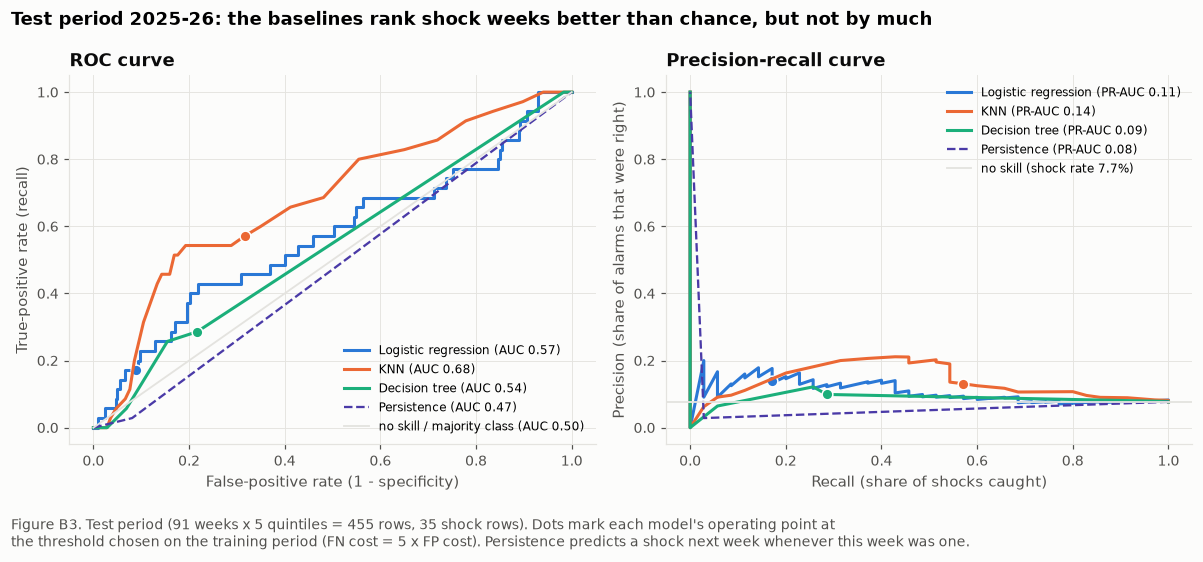

In [14]:
# Figure B3: ROC and precision-recall curves on the test period
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.6))
for n in MODELS + ["Persistence"]:
    fpr, tpr, _ = roc_curve(yt, p_test[n])
    a1.plot(fpr, tpr, color=COLORS[n], lw=2 if n in MODELS else 1.5, ls="-" if n in MODELS else "--",
            label=f"{n} (AUC {test_metrics.loc[n, 'ROC-AUC']:.2f})")
    pr, rc, _ = precision_recall_curve(yt, p_test[n])
    a2.plot(rc, pr, color=COLORS[n], lw=2 if n in MODELS else 1.5, ls="-" if n in MODELS else "--",
            label=f"{n} (PR-AUC {test_metrics.loc[n, 'PR-AUC']:.2f})")
    k = n in MODELS
    if k:   # mark the selected operating point
        m = test_metrics.loc[n]
        a1.plot(1 - m["specificity"], m["recall"], "o", color=COLORS[n], ms=7, mec="white")
        if m["alerts"] > 0:
            a2.plot(m["recall"], m["precision"], "o", color=COLORS[n], ms=7, mec="white")
a1.plot([0, 1], [0, 1], color=GRID, lw=1.2, label="no skill / majority class (AUC 0.50)")
a2.axhline(yt.mean(), color=GRID, lw=1.2, label=f"no skill (shock rate {yt.mean():.1%})")
a1.set(xlabel="False-positive rate (1 - specificity)", ylabel="True-positive rate (recall)", title="ROC curve")
a2.set(xlabel="Recall (share of shocks caught)", ylabel="Precision (share of alarms that were right)",
       title="Precision-recall curve")
a1.legend(fontsize=8, loc="lower right"); a2.legend(fontsize=8, loc="upper right")
fig.suptitle("Test period 2025-26: the baselines rank shock weeks better than chance, but not by much", x=0.01,
             ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
caption(fig, f"Figure B3. Test period (91 weeks x 5 quintiles = {len(yt)} rows, {int(yt.sum())} shock rows). Dots mark each model's operating point at\n"
             "the threshold chosen on the training period (FN cost = 5 x FP cost). Persistence predicts a shock next week whenever this week was one.")
fig.savefig(FIG_DIR / "figB3_roc_pr_test.png")
plt.show()

In [15]:
# Performance by quintile on the test period (a first look at the M4 fairness question, H5)
rows = []
for n in MODELS:
    for g in B.GROUPS:
        m = (test["group"] == g).to_numpy()
        r = B.classification_metrics(yt[m], p_test[n][m], thr[n])
        rows.append({"model": n, "group": g, "shock rows": int(yt[m].sum()), "caught (TP)": r["TP"],
                     "missed (FN)": r["FN"], "false alarms (FP)": r["FP"], "recall": r["recall"],
                     "specificity": r["specificity"], "ROC-AUC": r["ROC-AUC"], "Brier": r["Brier"]})
by_group = pd.DataFrame(rows)
display(by_group.pivot(index="group", columns="model", values=["recall", "ROC-AUC", "missed (FN)"]).round(2))
by_group.to_csv(TABLE_DIR / "m3_test_metrics_by_group.csv", index=False)

recall                                 ROC-AUC                             missed (FN)                         
model Decision tree   KNN Logistic regression Decision tree   KNN Logistic regression Decision tree  KNN Logistic regression
group                                                                                                                       
Q1             0.14  0.57                0.14          0.46  0.73                0.63           6.0  3.0                 6.0
Q2             0.44  0.44                0.11          0.59  0.68                0.52           5.0  5.0                 8.0
Q3             0.17  0.67                0.17          0.49  0.70                0.57           5.0  2.0                 5.0
Q4             0.29  0.57                0.14          0.57  0.67                0.55           5.0  3.0                 6.0
Q5             0.33  0.67                0.33          0.56  0.65                0.55           4.0  2.0                 4.0

**Reading the test results**

* **Accuracy is misleading here.** The majority class has the highest test accuracy (92.3%) and catches no shock
  at all. Every model has lower accuracy because it raises alarms. This is why accuracy is never the selection metric.
* **Ranking skill (ROC-AUC).** KNN 0.68 (95% week-bootstrap interval 0.47–0.83), logistic regression 0.57
  (0.35–0.76), tree 0.54 (0.43–0.67), and persistence 0.47 (shocks did not cluster in 2025–26). Only KNN's interval
  lies almost entirely above 0.5 (bootstrap share at or below 0.5: 5%). KNN had the highest test AUC, but that does
  not make it the best model: compared on the same resampled weeks, it ranked shocks better than logistic
  regression (difference +0.11, 95% CI +0.02 to +0.22) but not clearly better than the tree (+0.14, −0.04 to
  +0.29), and the test has only 13 shock weeks. PR-AUCs of 0.09–0.14 sit only a little above
  the no-skill line of 0.077.
* **At the chosen thresholds,** KNN caught 20 of the 35 shock rows (recall 0.57) at the price of 133 false alarms
  (precision 0.13, specificity 0.68). Logistic regression caught 6 (recall 0.17) with 37 false alarms; the tree caught
  10 (0.29) with 91. F1 is 0.15–0.21.
* **Validation years vs test.** Out-of-fold in 2021–24, recall was 0.58–0.79 and precision 0.26–0.38. In 2025–26,
  precision fell to 0.10–0.14. With a shock rate of 8% instead of about 19%, even a reasonable ranking produces mostly
  false alarms (the base-rate effect).
* **Calibration (Brier).** KNN (0.070) and the tree (0.078) are slightly better than the majority class (0.080).
  Logistic regression (0.238) is poor because its probabilities sit near 0.5 (balanced weights plus heavy shrinkage):
  usable for ranking, not as a probability.
* **By quintile** there are only 6–9 shock rows per group, so these numbers are fragile. Logistic regression and the
  tree caught 1 of 7 Q1 shock rows (recall 0.14) against 2 of 6 for Q5 (0.33); KNN caught 4 of 7 and 4 of 6. This
  first hint that the system serves the poorest worse (H5) will be tested properly in M4.

## 7. Asymmetric error costs (rubric C)

The two errors have very different social consequences:

| | **False positive (false alarm)** | **False negative (missed shock)** |
|---|---|---|
| What happened | the system warned of a shock that did not come | a shock came without warning |
| Households | receive an early or unneeded top-up, which still reaches poor families and is spent on essentials | face a sudden, lasting jump in the price of food or energy with no buffer. Coping is often irreversible: skipped meals, cheaper and less nutritious food, borrowing, selling assets |
| Government (BISP) | spends fiscal space that had other uses; repeated false alarms erode trust in the warnings ("cry wolf") | relief, if any, comes weeks late through the usual reactive channels |
| Markets | a public warning could itself feed price expectations or hoarding | none from the forecast itself |
| Reversible? | largely: the money is a transfer, not a loss to society | largely not, especially for child nutrition |

**Putting numbers on it.**
* *Shocks do not reverse* (cell below, training weeks only). Eight weeks after a Q1 shock week, prices were a median
  **4.2% above** the week before the shock, against 1.9% over the same span around an ordinary week (prices drift up
  even without a shock). The shock's own step is not given back: over the eight weeks after it, prices kept rising at
  about the usual pace (2.1% against 2.0%). A missed shock is a lasting step in the cost of living, not a one-week blip.
* *Size for a poor household.* A typical shock week raises Q1's SPI by 1.6% (median) to 2.0% (mean). On a monthly
  budget at the Q1 ceiling of Rs 17,732, a 2% rise in the prices of SPI items is up to about **Rs 355 a month**,
  roughly 8% of the monthly value of the BISP Kafaalat stipend (Rs 13,500 a quarter, about Rs 4,500 a month, since
  January 2025).
* *Fiscal scale of a false alarm.* An emergency top-up of one month's stipend to about 10 million Kafaalat families
  would cost about Rs 45 billion, but that money reaches poor households either way, so the true social cost of a
  false alarm is its opportunity cost, much smaller than its budget line.
* *Evidence that acting early pays.* FAO's evaluation of early action before Mongolia's 2017/18 dzud found about
  **US$7 of avoided losses and added benefits per US$1** spent.

**Our assumption.** We set the cost of a missed shock at **five** false alarms (FN:FP = 5:1). It is below the
FAO return because our false alarms are not pure waste, and above 1 because missed shocks harm the poor
irreversibly. Because any single ratio is a value judgement, all results are repeated for ratios from 1:1 to 20:1.

In [16]:
# How big and how lasting is a shock for the poorest quintile? (training weeks only, so the cost assumption
# does not look at the test period)
full_q1 = pd.read_csv(ROOT / "data" / "processed" / "master_features.csv", parse_dates=["week_end"])
full_q1 = full_q1[(full_q1["group"] == "Q1") & (full_q1["week_end"] <= B.TRAIN_END)].set_index("week_end")
is_shock = full_q1["spi_wow_pct"] >= 1
level_8w_later = (full_q1["log_spi"].shift(-8) - full_q1["log_spi"].shift(1)) * 100   # vs the week before the shock
size = full_q1.loc[is_shock, "spi_wow_pct"]
print(f"Q1 shock weeks 2019-24: {is_shock.sum()}; size median {size.median():.2f}%, mean {size.mean():.2f}%")
# Compare with ordinary weeks over the same span, because prices drift up even without a shock
after_8w = (full_q1["log_spi"].shift(-8) - full_q1["log_spi"]) * 100     # change over the 8 weeks after the week itself
print(f"Q1's SPI 8 weeks later vs the week before: median {level_8w_later[is_shock].median():.1f}% around a shock week, "
      f"{level_8w_later[~is_shock].median():.1f}% around an ordinary week")
print(f"Change over the 8 weeks after the week itself: median {after_8w[is_shock].median():.1f}% after a shock week, "
      f"{after_8w[~is_shock].median():.1f}% after an ordinary week (the shock's step is not given back)")
Q1_CEILING, KAFAALAT_QUARTER = 17_732, 13_500          # Rs per month (PBS Q1 ceiling); Rs per quarter (BISP, 2025)
print(f"2% of a Rs {Q1_CEILING:,} monthly budget = Rs {0.02 * Q1_CEILING:,.0f} a month "
      f"= {0.02 * Q1_CEILING / (KAFAALAT_QUARTER / 3):.0%} of the monthly Kafaalat value (Rs {KAFAALAT_QUARTER / 3:,.0f})")

Q1 shock weeks 2019-24: 45; size median 1.58%, mean 2.00%
Q1's SPI 8 weeks later vs the week before: median 4.2% around a shock week, 1.9% around an ordinary week
Change over the 8 weeks after the week itself: median 2.1% after a shock week, 2.0% after an ordinary week (the shock's step is not given back)
2% of a Rs 17,732 monthly budget = Rs 355 a month = 8% of the monthly Kafaalat value (Rs 4,500)


In [17]:
# Sensitivity to the cost ratio: re-choose each threshold on the training period, then score the test period
rows = []
for r in B.COST_RATIOS:
    triv_oof, triv_test = B.trivial_policy_costs(y[val], 1, r), B.trivial_policy_costs(yt, 1, r)
    best_oof, best_test = min(triv_oof.values()), min(triv_test.values())
    for n in MODELS + ["Persistence"]:
        t = B.best_threshold(y, oof[n], 1, r) if n in MODELS else 0.5
        c_oof = B.expected_cost(y[val], oof[n][val], t, 1, r)
        c_test = B.expected_cost(yt, p_test[n], t, 1, r)
        m = B.classification_metrics(yt, p_test[n], t, 1, r)
        rows.append({"FN:FP": r, "model": n, "threshold": t, "relative cost, validation years": c_oof / best_oof,
                     "relative cost, test": c_test / best_test, "test alerts": m["alerts"], "test recall": m["recall"],
                     "best trivial policy (test)": min(triv_test, key=triv_test.get)})
sens = pd.DataFrame(rows)
display(sens.pivot(index="FN:FP", columns="model", values="relative cost, test").round(2))
display(sens.pivot(index="FN:FP", columns="model", values="relative cost, validation years").round(2))
sens.to_csv(TABLE_DIR / "m3_cost_sensitivity.csv", index=False)

model,Decision tree,KNN,Logistic regression,Persistence
FN:FP,,,,
1,1.00,1.00,1.00,1.94
2,2.01,1.03,1.00,1.46
3,1.58,1.19,1.00,1.30
5,1.23,1.19,1.04,1.17
10,1.18,1.18,1.20,1.07
20,1.00,0.99,1.00,1.70


model,Decision tree,KNN,Logistic regression,Persistence
FN:FP,,,,
1,1.00,1.00,0.97,1.34
2,0.90,0.95,0.89,1.00
3,0.74,0.84,0.86,0.89
5,0.74,0.79,0.82,0.97
10,1.15,1.04,1.00,1.79
20,1.62,1.10,1.00,3.41


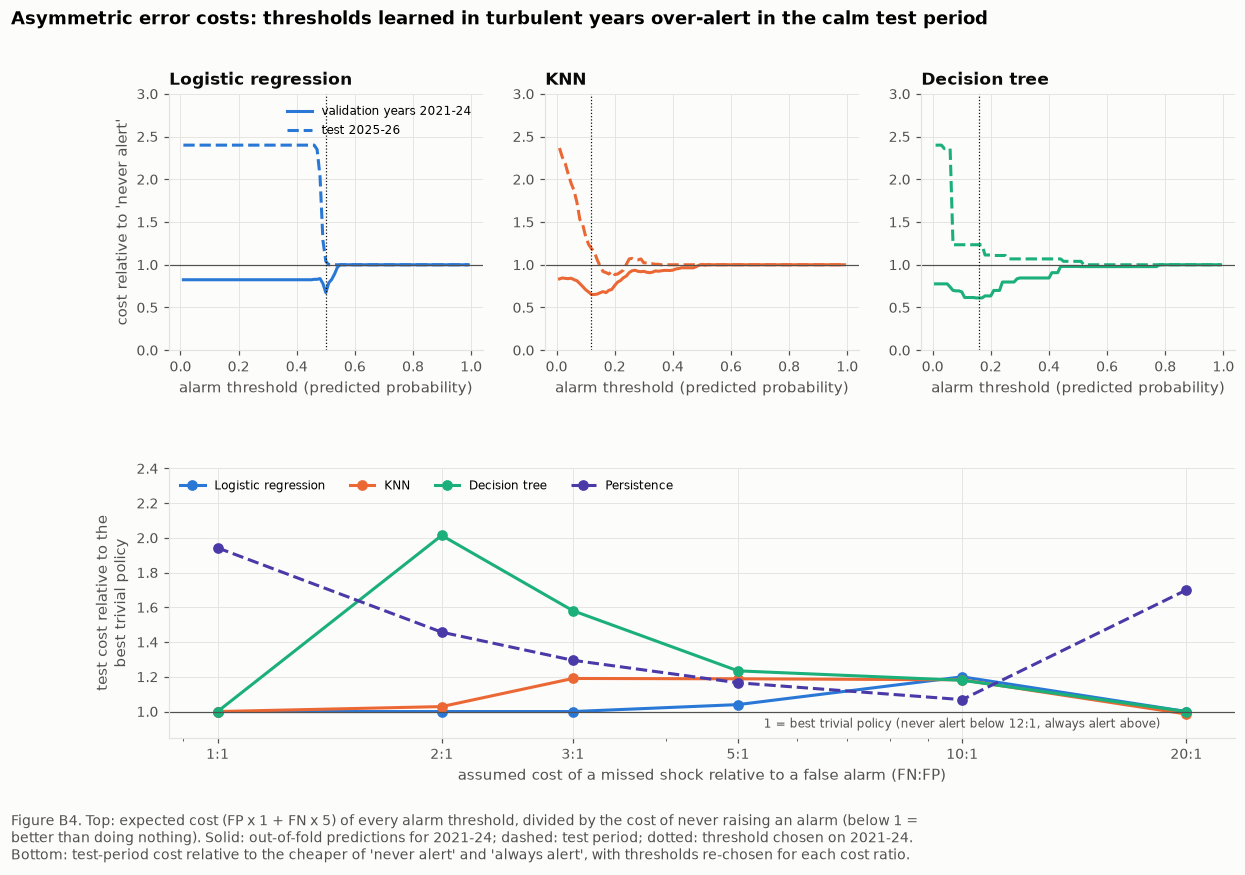

In [18]:
# Figure B4: cost of each alarm threshold, and sensitivity to the cost ratio
fig = plt.figure(figsize=(12.5, 7.6))
gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.05], hspace=0.45)
grid_t = np.round(np.arange(0.01, 1.0, 0.01), 2)
for i, n in enumerate(MODELS):
    ax = fig.add_subplot(gs[0, i])
    for yy, pp, lab, ls in [(y[val].to_numpy(), oof[n][val], "validation years 2021-24", "-"),
                            (yt.to_numpy(), p_test[n], "test 2025-26", "--")]:
        never = B.COST_FN * yy.sum()
        ax.plot(grid_t, [B.expected_cost(yy, pp, t) / never for t in grid_t], color=COLORS[n], ls=ls, label=lab)
    ax.axhline(1, color=INK_SECONDARY, lw=0.8)
    ax.axvline(thr[n], color=INK, lw=0.8, ls=":")
    ax.set_ylim(0, 3)
    ax.set_title(n, fontsize=11)
    ax.set_xlabel("alarm threshold (predicted probability)")
    if i == 0:
        ax.set_ylabel("cost relative to 'never alert'")
        ax.legend(fontsize=8, loc="upper right")
ax = fig.add_subplot(gs[1, :])
for n in MODELS + ["Persistence"]:
    s = sens[sens["model"] == n]
    ax.plot(s["FN:FP"], s["relative cost, test"], marker="o", color=COLORS[n], ls="-" if n in MODELS else "--", label=n)
ax.axhline(1, color=INK_SECONDARY, lw=0.8)
cross = (len(yt) - yt.sum()) / yt.sum()   # FN:FP ratio at which never-alert and always-alert cost the same
ax.text(10, 0.965, f"1 = best trivial policy (never alert below {cross:.0f}:1, always alert above)", fontsize=8,
        color=INK_SECONDARY, ha="center", va="top")
ax.set_ylim(0.85, 2.4)
ax.set_xscale("log")
ax.set_xticks(B.COST_RATIOS, [f"{r}:1" for r in B.COST_RATIOS])
ax.set_xlabel("assumed cost of a missed shock relative to a false alarm (FN:FP)")
ax.set_ylabel("test cost relative to the\nbest trivial policy")
ax.legend(fontsize=8, ncol=4, loc="upper left")
fig.suptitle("Asymmetric error costs: thresholds learned in turbulent years over-alert in the calm test period",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
caption(fig, "Figure B4. Top: expected cost (FP x 1 + FN x 5) of every alarm threshold, divided by the cost of never raising an alarm (below 1 =\n"
             "better than doing nothing). Solid: out-of-fold predictions for 2021-24; dashed: test period; dotted: threshold chosen on 2021-24.\n"
             "Bottom: test-period cost relative to the cheaper of 'never alert' and 'always alert', with thresholds re-chosen for each cost ratio.",
        y=0.02)
fig.savefig(FIG_DIR / "figB4_cost_analysis.png")
plt.show()

**Reading the cost analysis**

* **In the validation years (2021–24), all three models beat both trivial policies.** At 5:1 their out-of-fold cost is
  33–39% below the cost of never raising an alarm (Figure B4, top, solid lines). It is also 18–26% below alerting every
  week, which was the cheaper trivial policy in those years because the shock rate (19.5%) was above 1/6 (relative
  cost 0.74 for the tree, 0.79 for KNN, 0.82 for logistic regression). Persistence barely beats the cheaper trivial
  policy (0.97).
* **In the test period they do not.** At the same thresholds, costs are 4–23% *above* never alerting (logistic
  regression 1.04, KNN 1.19, tree 1.23). Figure B4 (top) shows why. At every low threshold the dashed test curve
  lies above the solid validation curve: thresholds that paid off when one quintile-week in five was followed by a
  shock produce too many false alarms when only one in thirteen is.
* **The ranking skill is there, but the threshold does not transfer.** KNN's dashed test curve does dip below 1
  (to about 0.89) for thresholds between 0.15 and 0.23. A higher threshold would have paid off, but that is an
  after-the-fact observation and cannot be used to choose the threshold.
* **Sensitivity to the cost ratio.** At 1:1 to 3:1 the cheapest trivial policy in both periods is to stay
  silent. At 1:1 the models learn to do so. At 2:1 and 3:1 their thresholds still beat silence in 2021–24 (relative
  cost 0.74–0.95) but over-alert in 2025–26 (1.00–2.01, worst for the tree). At 10:1 they alert almost every week, which is no better than the trivial policies.
  At 20:1, alerting every week is the cheapest trivial policy in the test period (420 false alarms cost less than
  35 × 20 missed shocks), and the models match it. **No ratio makes the baselines clearly valuable in 2025–26.**
  The 5:1 conclusion is not an artefact of the chosen ratio.
* **Policy reading:** an alarm calibrated on crisis years cries wolf in calm years. Thresholds must be revisited as
  the shock rate changes. That is the job of retraining as new weeks arrive (M5) and of calibration (M4).

## 8. Confusion matrices and misclassified edge cases (rubric C)

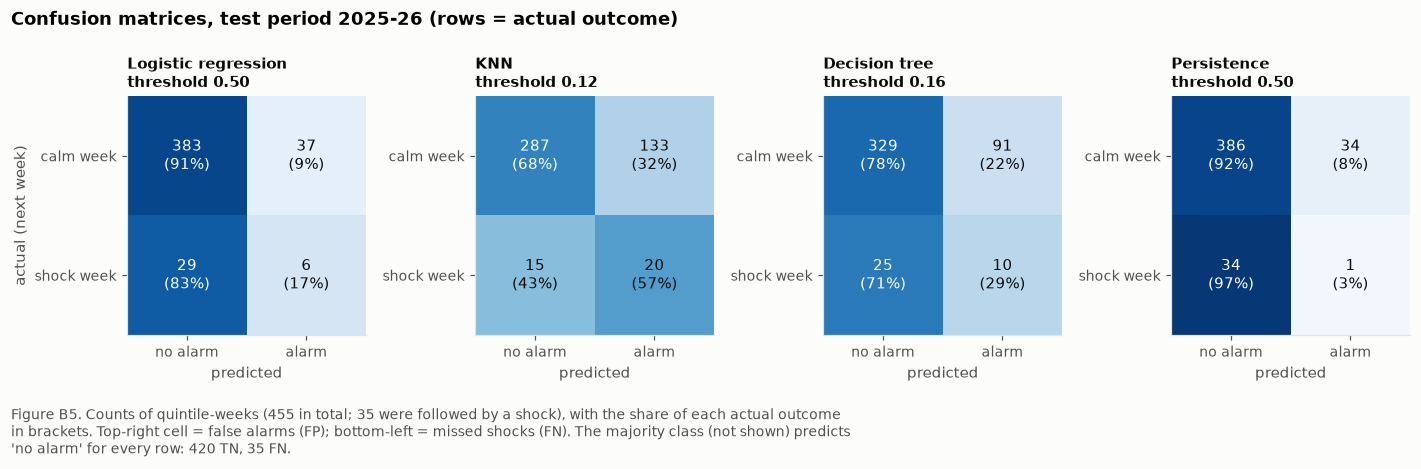

In [19]:
# Figure B5: confusion matrices on the test period at the training-period thresholds
show = MODELS + ["Persistence"]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
for ax, n in zip(axes, show):
    m = test_metrics.loc[n]
    cm = np.array([[m["TN"], m["FP"]], [m["FN"], m["TP"]]], dtype=float)
    share = cm / cm.sum(axis=1, keepdims=True)                      # row shares: of actual calm / actual shock rows
    ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{int(cm[i, j])}\n({share[i, j]:.0%})", ha="center", va="center", fontsize=10,
                    color="white" if share[i, j] > 0.6 else INK)
    ax.set_xticks([0, 1], ["no alarm", "alarm"])
    ax.set_yticks([0, 1], ["calm week", "shock week"])
    ax.grid(False)
    ax.set_title(f"{n}\nthreshold {thr[n]:.2f}", fontsize=10)
    ax.set_xlabel("predicted")
axes[0].set_ylabel("actual (next week)")
fig.suptitle("Confusion matrices, test period 2025-26 (rows = actual outcome)", x=0.01, ha="left", fontsize=12,
             fontweight="bold")
fig.tight_layout()
caption(fig, f"Figure B5. Counts of quintile-weeks ({len(yt)} in total; {int(yt.sum())} were followed by a shock), with the share of each actual outcome\n"
             "in brackets. Top-right cell = false alarms (FP); bottom-left = missed shocks (FN). The majority class (not shown) predicts\n"
             f"'no alarm' for every row: {int((yt == 0).sum())} TN, {int(yt.sum())} FN.")
fig.savefig(FIG_DIR / "figB5_confusion_matrices.png")
plt.show()

In [20]:
# Every shock in the test period: when it hit, what drove it, and which models had raised an alarm the week before
items = pd.read_csv(ROOT / "data" / "processed" / "items_weekly_panel.csv", parse_dates=["week_end"])
items["component"] = [component(i, c) for i, c in zip(items["item_id"], items["category"])]
# PBS item impact (pp of the Combined SPI change); where PBS published none (unpublished weeks), weight x % change
items["impact"] = items["impact_combined"].fillna(items["weight_combined"] * items["price_wow_pct"] / 100)

ev = test.assign(shock_week=test["week_end"] + pd.Timedelta(days=7))
for n in MODELS:
    ev[f"alert {n}"] = (p_test[n] >= thr[n]).astype(int)
rows = []
for w, g in ev[ev[B.TARGET] == 1].groupby("shock_week"):
    top = items[items["week_end"] == w].nlargest(2, "impact")     # the largest upward contributions to the rise
    drv = "; ".join(f"{r.item_id} {r.price_wow_pct:+.0f}%" for r in top.itertuples())
    rows.append({"shock week": w.date(), "groups shocked": ",".join(g["group"]), "mean SPI rise %": g["target_spi_wow_pct_next"].mean(),
                 "main driver (item, weekly change)": drv, "driver component": top["component"].iloc[0],
                 **{f"{n} caught": f"{g[f'alert {n}'].sum()}/{len(g)}" for n in MODELS}})
edge = pd.DataFrame(rows)
display(edge.round(2))
edge.to_csv(TABLE_DIR / "m3_test_shock_weeks.csv", index=False)

,shock week,groups shocked,mean SPI rise %,"main driver (item, weekly change)",driver component,Logistic regression caught,KNN caught,Decision tree caught
0,2025-05-15,"Q2,Q4,Q5",1.04,chicken +16%; long_cloth +2%,perishables,0/3,0/3,0/3
1,2025-07-10,"Q1,Q2,Q4",1.06,chicken +23%; tomatoes +13%,perishables,0/3,1/3,2/3
2,2025-07-24,"Q1,Q2,Q3,Q4,Q5",4.08,gas_q1 +30%; electricity_q1 +21%,utilities,0/5,5/5,1/5
3,2025-09-04,"Q1,Q2,Q3,Q4",1.75,wheat_flour +25%; tomatoes +46%,staples,0/4,4/4,2/4
4,2025-10-16,Q1,1.07,tomatoes +33%; onions +9%,perishables,0/1,0/1,0/1
5,2026-02-19,"Q1,Q2,Q3",1.21,electricity_q1 +15%; bananas +16%,utilities,0/3,0/3,0/3
6,2026-03-12,"Q3,Q4,Q5",1.70,petrol +21%; lpg +12%,motor_fuel,0/3,0/3,0/3
7,2026-03-26,Q2,1.09,electricity_q1 +6%; lpg +10%,utilities,0/1,0/1,0/1
8,2026-04-02,Q5,1.15,milk_fresh +1%; lpg +13%,staples,1/1,1/1,1/1
9,2026-04-09,"Q2,Q3,Q4,Q5",1.56,petrol +18%; lpg +9%,motor_fuel,4/4,4/4,4/4


In [21]:
# Systematic pattern 1: which kinds of shock are caught?
ev2 = ev[ev[B.TARGET] == 1].merge(edge[["shock week", "driver component"]].assign(**{"shock week": lambda d: pd.to_datetime(d["shock week"])}),
                                  left_on="shock_week", right_on="shock week")
by_src = ev2.groupby("driver component")[[f"alert {n}" for n in MODELS]].agg(["sum", "size"])
by_src = pd.DataFrame({n: by_src[(f"alert {n}", "sum")].astype(str) + "/" + by_src[(f"alert {n}", "size")].astype(str)
                       for n in MODELS})
print("Shock rows caught, by the component that drove the shock:")
display(by_src)

# Systematic pattern 2: what was going on in the weeks with false alarms?
flags = {"fuel review next week": test["fuel_review_next_week"] == 1, "fiscal year starts next week": test["fy_start_next_week"] == 1,
         "rupee fell >2% in 8 weeks": test["fx_chg_8w"] > 2, "shock in past 4 weeks": test["shocks_last_4w"] >= 1}
rows = []
for n in MODELS:
    fa = ((p_test[n] >= thr[n]) & (yt == 0)).to_numpy()
    rows.append({"model": n, "false alarms": int(fa.sum()), **{k: f"{100 * v[fa].mean():.0f}%" for k, v in flags.items()}})
rows.append({"model": "all test rows", "false alarms": len(test), **{k: f"{100 * v.mean():.0f}%" for k, v in flags.items()}})
fa_tab = pd.DataFrame(rows).set_index("model")
print("Share of false alarms raised in weeks with each signal (last row: share of all test rows):")
display(fa_tab)
fa_tab.to_csv(TABLE_DIR / "m3_false_alarm_profile.csv")

# Systematic pattern 3: when in the year do the test shocks fall?
month = pd.to_datetime(edge["shock week"]).dt.month_name()
print("Test shock weeks by calendar month:", month.value_counts().to_dict())

Shock rows caught, by the component that drove the shock:


,Logistic regression,KNN,Decision tree
driver component,,,
motor_fuel,4/7,4/7,4/7
perishables,1/13,6/13,2/13
staples,1/5,5/5,3/5
utilities,0/10,5/10,1/10


Share of false alarms raised in weeks with each signal (last row: share of all test rows):


,false alarms,fuel review next week,fiscal year starts next week,rupee fell >2% in 8 weeks,shock in past 4 weeks
model,,,,,
Logistic regression,37,65%,24%,0%,73%
KNN,133,50%,1%,0%,68%
Decision tree,91,47%,0%,0%,75%
all test rows,455,46%,2%,0%,27%


Test shock weeks by calendar month: {'July': 4, 'September': 2, 'March': 2, 'April': 2, 'May': 1, 'October': 1, 'February': 1}


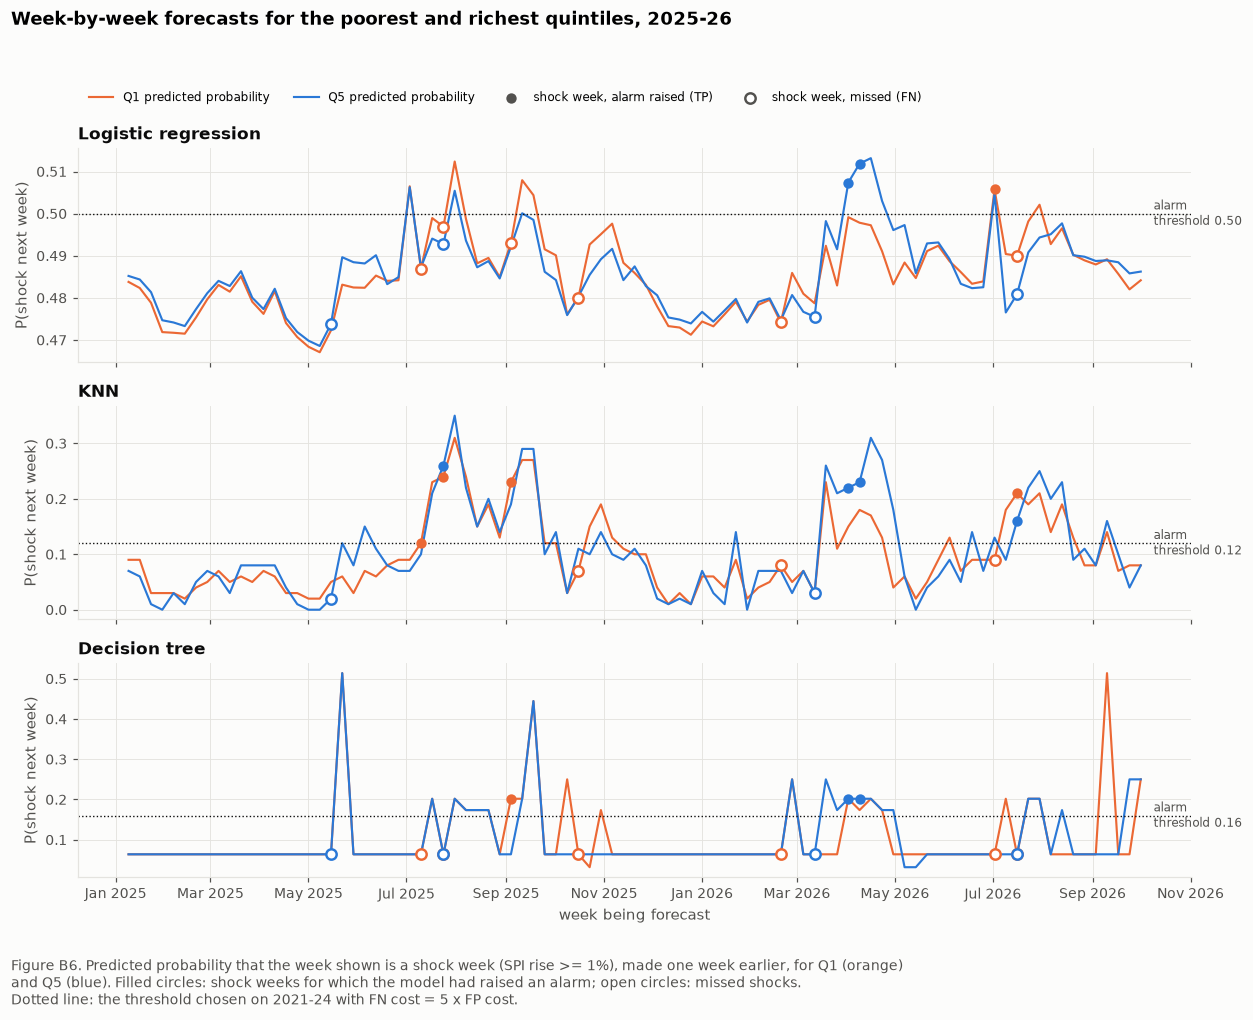

In [22]:
# Figure B6: the forecasts week by week for Q1 (poorest) and Q5 (richest)
fig, axes = plt.subplots(3, 1, figsize=(11.5, 8.2), sharex=True)
for ax, n in zip(axes, MODELS):
    for g in ["Q1", "Q5"]:
        s = ev[ev["group"] == g]
        p = p_test[n][(test["group"] == g).to_numpy()]
        ax.plot(s["shock_week"], p, color=GROUP_COLORS[g], lw=1.4, label=f"{g} predicted probability")
        hit = s[(s[B.TARGET] == 1) & (s[f"alert {n}"] == 1)]
        miss = s[(s[B.TARGET] == 1) & (s[f"alert {n}"] == 0)]
        ph = p[(s[B.TARGET] == 1).to_numpy() & (s[f"alert {n}"] == 1).to_numpy()]
        pm = p[(s[B.TARGET] == 1).to_numpy() & (s[f"alert {n}"] == 0).to_numpy()]
        ax.scatter(hit["shock_week"], ph, s=46, color=GROUP_COLORS[g], edgecolor="white", zorder=3)
        ax.scatter(miss["shock_week"], pm, s=46, facecolor="white", edgecolor=GROUP_COLORS[g], lw=1.6, zorder=3)
    ax.axhline(thr[n], color=INK, lw=0.9, ls=":")
    ax.text(ev["shock_week"].max() + pd.Timedelta(days=8), thr[n], f"alarm\nthreshold {thr[n]:.2f}", va="center",
            fontsize=8, color=INK_SECONDARY)
    ax.set_title(n, fontsize=11)
    ax.set_ylabel("P(shock next week)")
axes[0].scatter([], [], s=46, color=INK_SECONDARY, label="shock week, alarm raised (TP)")
axes[0].scatter([], [], s=46, facecolor="white", edgecolor=INK_SECONDARY, lw=1.6, label="shock week, missed (FN)")
axes[0].legend(fontsize=8, ncol=4, loc="upper left", bbox_to_anchor=(0, 1.32))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
axes[-1].set_xlabel("week being forecast")
fig.suptitle("Week-by-week forecasts for the poorest and richest quintiles, 2025-26", x=0.01, ha="left",
             fontsize=12, fontweight="bold", y=1.03)
fig.tight_layout()
caption(fig, "Figure B6. Predicted probability that the week shown is a shock week (SPI rise >= 1%), made one week earlier, for Q1 (orange)\n"
             "and Q5 (blue). Filled circles: shock weeks for which the model had raised an alarm; open circles: missed shocks.\n"
             "Dotted line: the threshold chosen on 2021-24 with FN cost = 5 x FP cost.")
fig.savefig(FIG_DIR / "figB6_test_timeline.png")
plt.show()

**Systematic weaknesses revealed by the errors**

1. **First waves are missed; repeats are caught.** The March 2026 petrol increase (+21%) was missed by all three models
   for all three groups it hit. The second increase four weeks later (+18%) was caught by all three models for all
   four groups. The models follow momentum: after one shock, `shocks_last_4w` and motor-fuel inflation rise and the
   alarm switches on. Nothing in the data warns of the *first* move of a new episode.
2. **Administered utility tariffs are largely missed.** Gas and electricity tariff increases drove 4 of the 13 shock
   weeks (10 shock rows). Logistic regression caught 0 of the 10 and the tree 1. KNN's five catches are all the July 2025
   tariff week, which came two weeks after an earlier shock, so they reflect momentum, not foresight of the tariff. Tariff
   decisions are announced on irregular dates and none of our features records them.
3. **Perishable spikes are mostly missed** (chicken, tomatoes: 13 shock rows). Logistic regression caught 1 and the
   tree 2. KNN caught 6, five of them in July 2026, again right after another shock. Weather and supply shocks have no lead
   signal in our data.
4. **False alarms follow shocks.** 68–75% of false alarms were raised in the weeks after a recent shock, while only 27% of
   all test rows follow one. Once a shock has passed, the momentum features keep the alarm on (Figure B6, April–May
   2026). Logistic regression's false alarms also lean towards fuel-review weeks (65% against 46% of all rows).
5. **The strongest training signal never switched on.** The rupee did not fall by more than 2% over 8 weeks in any test
   week. The exchange-rate signal, which is the tree's first split and logistic regression's largest weight, had
   nothing to warn about in 2025–26.
6. **July carries the most risk, beyond its first week.** Four of the 13 test shock weeks (14 of the 35 shock rows) fell
   in July 2025 or July 2026, but only one of them was the week containing 1 July, which is all that
   `fy_start_next_week` flags. Budget measures and tariff rebasing take effect over several weeks; a "first month of the
   fiscal year" feature is a candidate for M4.

## 9. Feature importance: what drives the forecasts? (rubric D)

Three complementary measures, because each model "sees" features differently:
* **Logistic regression: standardised coefficients.** All features are z-scored, so each coefficient is the change in
  log-odds for a one-standard-deviation change in that feature, comparable across features. The tuned model is
  heavily shrunk (very small `C`), so we show the coefficients *relative to the largest*. For effects in natural units
  (e.g. per 1% rupee depreciation), we also fit the **unpenalised** logit on the same 18 features and report **odds
  ratios** with 95% confidence intervals. Their standard errors are clustered by week: the five quintile rows of a
  week share the same signals, so they count as one block of evidence, not five.
* **Decision tree: Gini importance.** The share of the tree's total reduction in Gini impurity (class mixing, Units 08–09)
  that comes from splits on each feature. It only credits features the tree actually used.
* **Permutation importance (all three models).** Shuffle one feature's values in a validation year, which breaks its
  link with the target, and measure how much the validation AUC falls. It works for any model, including KNN, which has
  no coefficients. It is computed on the 2021–24 validation folds, so the test period is not used to judge features.

In [23]:
# (a) Logistic regression: standardised coefficients of the tuned (heavily shrunk) model
lr = fitted["Logistic regression"].named_steps["model"]
coef = pd.Series(lr.coef_[0], index=B.FEATURES)
# (b) Unpenalised logit with all 18 features: odds ratios in natural units, week-clustered 95% CIs
full18 = B.fit_logit(train, B.FEATURES)
orr = pd.DataFrame({"odds ratio": np.exp(full18.params), "95% CI low": np.exp(full18.conf_int()[0]),
                    "95% CI high": np.exp(full18.conf_int()[1]), "p-value": full18.pvalues}).drop("const")
# (c) Decision tree: Gini importance (share of the total impurity reduction)
tree = fitted["Decision tree"].named_steps["model"]
gini = pd.Series(tree.feature_importances_, index=B.FEATURES)
# (d) Permutation importance on the validation years, all three models
perm = {n: B.cv_permutation_importance(fitted[n], X, y, folds).set_index("feature") for n in MODELS}

imp = pd.DataFrame({"label": [B.LABELS[f] for f in B.FEATURES],
                    "LR std. coefficient": coef, "LR relative weight": coef / coef.abs().max(),
                    "odds ratio (unpenalised)": orr["odds ratio"], "OR p-value": orr["p-value"],
                    "tree Gini importance": gini,
                    **{f"perm. AUC drop: {n}": perm[n]["mean AUC drop"] for n in MODELS}}, index=B.FEATURES)
imp["mean perm. drop"] = imp[[f"perm. AUC drop: {n}" for n in MODELS]].mean(axis=1)
imp = imp.sort_values("mean perm. drop", ascending=False)
display(imp.round(4))
imp.to_csv(TABLE_DIR / "m3_feature_importance.csv")
orr.to_csv(TABLE_DIR / "m3_odds_ratios.csv")
fy = train[train["fy_start_next_week"] == 1]
print(f"Fiscal-year-start weeks in training: {fy['week_end'].nunique()}; {int(fy[B.TARGET].sum())} of their {len(fy)} "
      f"quintile rows were followed by a shock ({fy[B.TARGET].mean():.0%}, against {y.mean():.0%} overall)")

,label,LR std. coefficient,LR relative weight,odds ratio (unpenalised),OR p-value,tree Gini importance,perm. AUC drop: Logistic regression,perm. AUC drop: KNN,perm. AUC drop: Decision tree,mean perm. drop
infl_perishables_4w,"Perishables inflation, past 4 weeks (%)",0.0098,0.4712,1.0418,0.0894,0.1739,0.0061,0.0569,0.0051,0.0227
shocks_last_4w,Shock weeks in past 4 weeks,0.0189,0.9090,1.2273,0.3336,0.0000,0.0129,0.0510,0.0000,0.0213
spi_chg_4w,"SPI change, past 4 weeks (%)",0.0122,0.5860,0.9917,0.9362,0.0445,0.0122,0.0235,0.0245,0.0201
fx_chg_8w,"PKR/USD change, past 8 weeks (%)",0.0208,1.0000,1.1070,0.0151,0.4502,0.0114,0.0265,0.0147,0.0175
infl_motor_fuel_4w,"Motor-fuel inflation, past 4 weeks (%)",0.0126,0.6059,1.0097,0.6764,0.0000,-0.0044,0.0259,0.0100,0.0105
infl_staples_4w,"Staple-food inflation, past 4 weeks (%)",0.0177,0.8527,1.1568,0.2658,0.1629,0.0046,-0.0094,0.0215,0.0056
momentum_spikes_4w,"Momentum-item spikes, past 4 weeks",0.0099,0.4778,0.9223,0.4631,0.0000,0.0017,0.0188,-0.0059,0.0049
spi_wow_pct,SPI change this week (%),0.0074,0.3548,0.9998,0.9989,0.1685,0.0068,0.0108,-0.0043,0.0044
fuel_review_next_week,Fuel-price review next week,0.0026,0.1246,1.0940,0.7791,0.0000,-0.0034,0.0135,0.0022,0.0041
policy_rate,SBP policy rate (%),0.0034,0.1621,1.0166,0.5818,0.0000,0.0043,0.0064,0.0013,0.0040


Fiscal-year-start weeks in training: 5; 14 of their 25 quintile rows were followed by a shock (56%, against 17% overall)


In [24]:
# The five leading drivers: the first five rows of the importance table (sorted by mean permutation importance)
top5 = imp.head(5)[["label", "mean perm. drop", "tree Gini importance",
                    "odds ratio (unpenalised)", "OR p-value"]].copy()
top5.insert(0, "rank", range(1, 6))
display(top5.round(3))
top5.to_csv(TABLE_DIR / "m3_top5_drivers.csv", index=False)

,rank,label,mean perm. drop,tree Gini importance,odds ratio (unpenalised),OR p-value
infl_perishables_4w,1,"Perishables inflation, past 4 weeks (%)",0.023,0.174,1.042,0.089
shocks_last_4w,2,Shock weeks in past 4 weeks,0.021,0.000,1.227,0.334
spi_chg_4w,3,"SPI change, past 4 weeks (%)",0.020,0.044,0.992,0.936
fx_chg_8w,4,"PKR/USD change, past 8 weeks (%)",0.018,0.450,1.107,0.015
infl_motor_fuel_4w,5,"Motor-fuel inflation, past 4 weeks (%)",0.011,0.000,1.010,0.676


**The five leading drivers and what they mean for policy**

| Rank | Driver | Policy implication |
|---|---|---|
| 1 | Perishables inflation, past 4 weeks | Track weekly prices of perishables (tomatoes, onions, chicken): a four-week run-up is the most useful warning sign, and food shocks widen the inflation gap against the poorest (H3, notebook 04). |
| 2 | Shock weeks in past 4 weeks | Shocks cluster: after a first shock week, keep BISP top-ups on standby for the following month. |
| 3 | SPI change, past 4 weeks | Monitor each quintile's own four-week inflation, not only the weekly change: the models use a recent build-up as a warning sign. |
| 4 | PKR/USD change, past 8 weeks | Watch the rupee: a fall of several percent over two months should trigger a readiness review of top-ups; it raises every quintile's prices alike (H2, notebook 04). |
| 5 | Motor-fuel inflation, past 4 weeks | Fuel prices are reviewed every fortnight on known dates, so this signal can be anticipated; motor fuel weighs more in richer baskets, so its direct burden falls mostly on Q5 (H3). |

Importance shows what the models rely on, not cause and effect, and it varies between folds (Figure B7), so these are
directions for monitoring rather than proven levers.

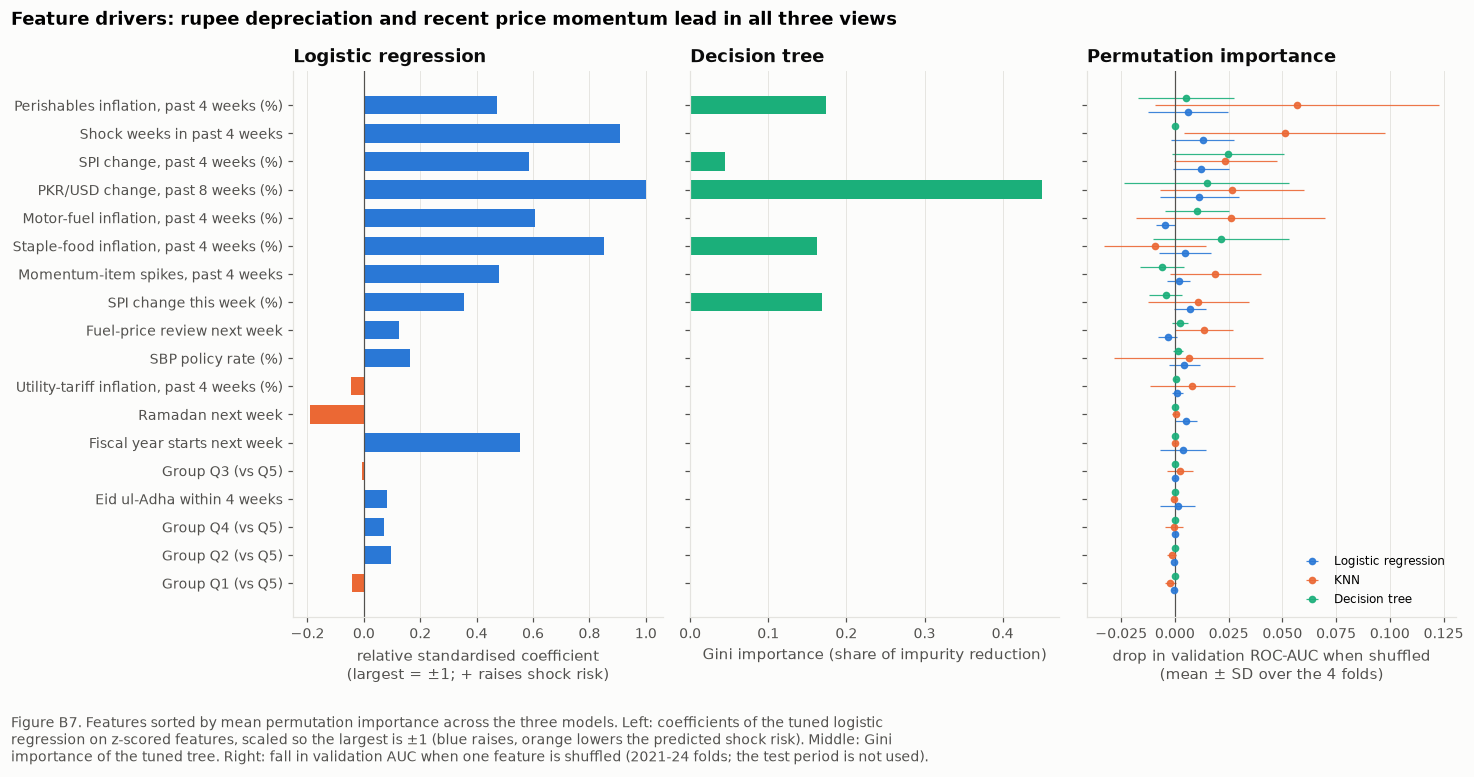

In [25]:
# Figure B7: three views of what drives the forecasts
order = imp.index[::-1]
labels = [B.LABELS[f] for f in order]
yy = np.arange(len(order))
fig, axes = plt.subplots(1, 3, figsize=(13.5, 6.4), sharey=True)
ax = axes[0]
w = imp.loc[order, "LR relative weight"]
ax.barh(yy, w, color=[SERIES[0] if v > 0 else SERIES[1] for v in w], height=0.65)
ax.axvline(0, color=INK_SECONDARY, lw=0.8)
ax.set(xlabel="relative standardised coefficient\n(largest = ±1; + raises shock risk)", title="Logistic regression")
ax.set_yticks(yy, labels)
ax = axes[1]
ax.barh(yy, imp.loc[order, "tree Gini importance"], color=SERIES[2], height=0.65)
ax.set(xlabel="Gini importance (share of impurity reduction)", title="Decision tree")
ax = axes[2]
for k, n in enumerate(MODELS):
    off = (k - 1) * 0.25
    ax.errorbar(perm[n].loc[order, "mean AUC drop"], yy + off, xerr=perm[n].loc[order, "SD across folds"],
                fmt="o", ms=4, color=COLORS[n], ecolor=COLORS[n], elinewidth=0.8, alpha=0.9, label=n)
ax.axvline(0, color=INK_SECONDARY, lw=0.8)
ax.set(xlabel="drop in validation ROC-AUC when shuffled\n(mean ± SD over the 4 folds)", title="Permutation importance")
ax.legend(fontsize=8, loc="lower right")
for a in axes:
    a.grid(axis="y", visible=False)
fig.suptitle("Feature drivers: rupee depreciation and recent price momentum lead in all three views", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
fig.tight_layout()
caption(fig, "Figure B7. Features sorted by mean permutation importance across the three models. Left: coefficients of the tuned logistic\n"
             "regression on z-scored features, scaled so the largest is ±1 (blue raises, orange lowers the predicted shock risk). Middle: Gini\n"
             "importance of the tuned tree. Right: fall in validation AUC when one feature is shuffled (2021-24 folds; the test period is not used).")
fig.savefig(FIG_DIR / "figB7_feature_importance.png")
plt.show()

|--- fx_chg_8w <= 8.00
|   |--- spi_wow_pct <= 0.74
|   |   |--- infl_staples_4w <= 2.56
|   |   |   |--- spi_chg_4w <= 1.89
|   |   |   |   |--- class: 0
|   |   |   |--- spi_chg_4w >  1.89
|   |   |   |   |--- class: 0
|   |   |--- infl_staples_4w >  2.56
|   |   |   |--- class: 0
|   |--- spi_wow_pct >  0.74
|   |   |--- infl_perishables_4w <= 3.78
|   |   |   |--- infl_staples_4w <= 0.61
|   |   |   |   |--- class: 0
|   |   |   |--- infl_staples_4w >  0.61
|   |   |   |   |--- class: 0
|   |   |--- infl_perishables_4w >  3.78
|   |   |   |--- infl_perishables_4w <= 10.38
|   |   |   |   |--- class: 1
|   |   |   |--- infl_perishables_4w >  10.38
|   |   |   |   |--- class: 0
|--- fx_chg_8w >  8.00
|   |--- spi_wow_pct <= 0.79
|   |   |--- class: 1
|   |--- spi_wow_pct >  0.79
|   |   |--- class: 0



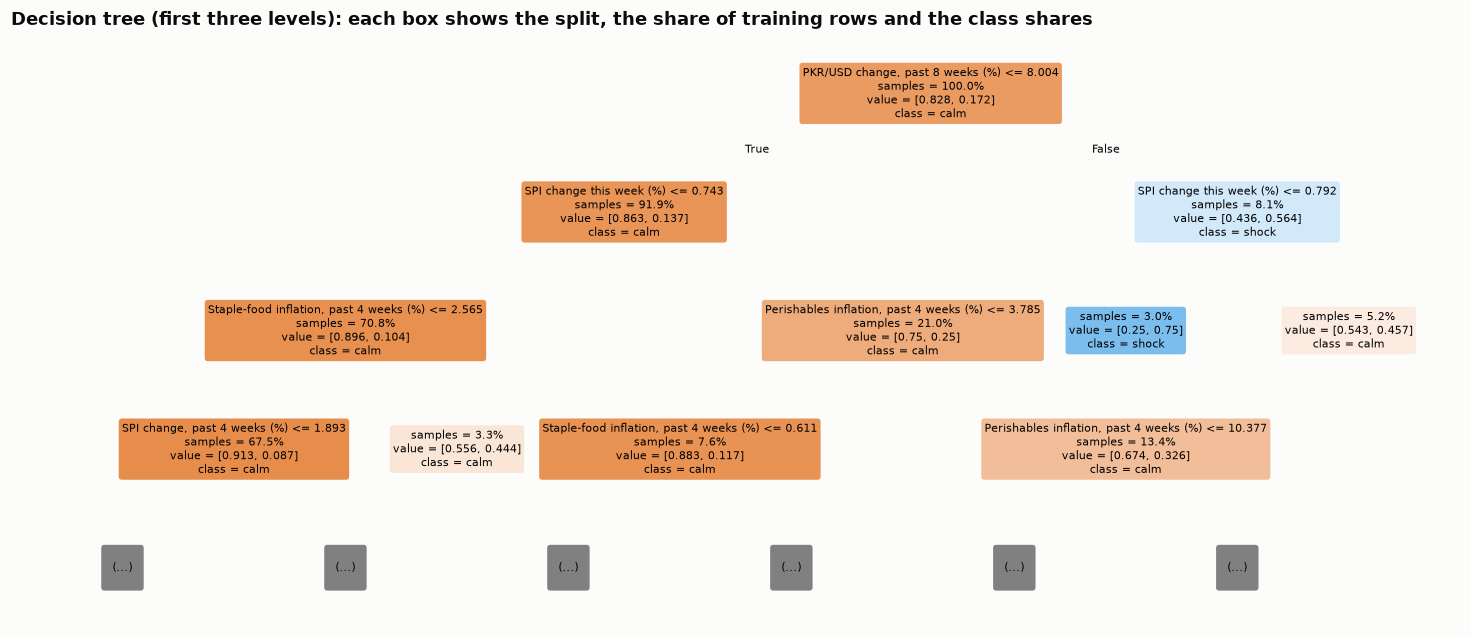

In [26]:
# The tuned tree as plain if-then rules (a transparent alarm rule a policy desk could read)
print(export_text(tree, feature_names=B.FEATURES, decimals=2, show_weights=False))
fig, ax = plt.subplots(figsize=(17, 7))
plot_tree(tree, feature_names=[B.LABELS[f] for f in B.FEATURES], class_names=["calm", "shock"], filled=True,
          impurity=False, proportion=True, rounded=True, fontsize=7, ax=ax, max_depth=3)
ax.set_title("Decision tree (first three levels): each box shows the split, the share of training rows and the class shares",
             loc="left")
fig.savefig(FIG_DIR / "figB8_decision_tree.png")
plt.show()

**Reading the drivers**

* **The methods agree on the top drivers.** The 8-week rupee depreciation is logistic regression's largest weight and
  the tree's first and most important split (Gini importance 0.45). Recent shocks, staple-food inflation and
  perishables inflation rank high in at least two of the three views. By permutation importance, perishables
  inflation, recent shocks, the 4-week SPI change and the rupee lead.
* **Odds ratios (unpenalised logit, natural units).** Each extra 1% of rupee depreciation over 8 weeks raises the odds
  of a shock next week by about 11% (odds ratio 1.11, p = 0.015). A fiscal-year start next week multiplies the odds
  by about 5 (OR 5.3, p = 0.013), but this rests on only five fiscal-year starts (14 of their 25 quintile rows
  were followed by a shock), so its 95% interval is wide (1.4–19.5). The fiscal-year start is strong but rare (2% of rows), so shuffling it barely moves
  permutation importance: **importance measures reward features that matter often, not features that matter a lot
  occasionally.**
* **What does not matter.** The quintile dummies are near zero in every view: once the signals are in, the five groups
  do not differ in their baseline shock risk. Ramadan is negative, as in M2. Eid ul-Adha is about zero. Utility-tariff
  momentum is about zero, because tariff increases are one-off steps, not trends.
* **KNN leans on more features** than the other two models (it cannot down-weight irrelevant ones), notably
  perishables inflation and recent shocks.
* Permutation importances vary a lot between folds (wide error bars), which fits a weak signal.

## 10. Formal test of hypothesis H1 (promised in M2)

From the M2 manuscript (§III-H): in logit P(*Y*<sub>g,t+1</sub> = 1) = α<sub>g</sub> + γ′*h*<sub>g,t</sub> + β′*s*<sub>t</sub>, where *h* is
the group's own history plus controls and *s* the six lead signals,

* **H0:** β = 0 (the signals carry no information about next week's shock), and the out-of-sample AUC of the signals
  model equals that of the own-history model;
* **H1:** at least one β ≠ 0, and the signals model's out-of-sample AUC is higher.

Tests at the 5% level, p-value approach (Unit 07):
1. **In-sample:** likelihood-ratio test of the six β's, and the same restriction as a **Wald test with standard errors
   clustered by week**. Clustering matters because the five quintile rows of a week share the same signals, so they
   are not five independent observations. The plain LR test ignores this and overstates the evidence.
2. **Out of sample:** the test-period AUCs of the two models, compared with a **week-block bootstrap** of their
   difference: resample whole test weeks with replacement 2,000 times and count how often the signals add nothing.
   M2 planned the DeLong test here. We replaced it because DeLong treats every row as independent, while the five
   quintile rows of a week move together; resampling whole weeks keeps them together, as the cross-validation does.

In [27]:
# In-sample (training period): does adding the six lead signals improve the own-history logit?
base = B.fit_logit(train, B.H1_BASE)
full = B.fit_logit(train, B.H1_FULL)
lr_stat = 2 * (full.llf - base.llf)
wald = full.wald_test(", ".join(f"{s} = 0" for s in B.SIGNALS), scalar=True)
print(f"Likelihood-ratio test: chi2({len(B.SIGNALS)}) = {lr_stat:.1f}, p = {stats.chi2.sf(lr_stat, len(B.SIGNALS)):.2g}"
      "  (assumes independent rows)")
print(f"Wald test, week-clustered SEs: chi2({len(B.SIGNALS)}) = {float(wald.statistic):.1f}, p = {float(wald.pvalue):.4f}")
sig = pd.DataFrame({"coefficient": full.params, "odds ratio": np.exp(full.params),
                    "95% CI low": np.exp(full.conf_int()[0]), "95% CI high": np.exp(full.conf_int()[1]),
                    "p-value": full.pvalues}).loc[B.SIGNALS]
sig.index = [B.LABELS[s] for s in B.SIGNALS]
display(sig.round(3))

Likelihood-ratio test: chi2(6) = 94.0, p = 4.5e-18  (assumes independent rows)
Wald test, week-clustered SEs: chi2(6) = 22.4, p = 0.0010


,coefficient,odds ratio,95% CI low,95% CI high,p-value
"PKR/USD change, past 8 weeks (%)",0.085,1.089,1.010,1.174,0.027
Shock weeks in past 4 weeks,0.359,1.432,0.976,2.101,0.066
"Momentum-item spikes, past 4 weeks",-0.014,0.986,0.796,1.221,0.898
"Staple-food inflation, past 4 weeks (%)",0.121,1.129,0.893,1.427,0.311
Fuel-price review next week,0.076,1.079,0.577,2.017,0.813
Fiscal year starts next week,1.646,5.185,1.379,19.492,0.015


In [28]:
# Out of sample: same two logits, refitted fold by fold (validation years) and once on all training weeks (test period)
def logit_oof(cols):
    p = np.full(len(train), np.nan)
    for tr, va in folds:
        p[va] = B.logit_predict(B.fit_logit(train.iloc[tr], cols), train.iloc[va], cols)
    return p

h1 = {}
for lab, cols, m in [("own history only", B.H1_BASE, base), ("own history + signals", B.H1_FULL, full)]:
    h1[lab] = {"oof": logit_oof(cols), "test": B.logit_predict(m, test, cols)}
bt = B.week_block_bootstrap(yt, {k: v["test"] for k, v in h1.items()}, test["week_end"])
diff = bt["own history + signals"] - bt["own history only"]
h1_tab = pd.DataFrame({
    "validation years AUC (pooled)": {k: roc_auc_score(y[val], v["oof"][val]) for k, v in h1.items()},
    "test AUC": {k: roc_auc_score(yt, v["test"]) for k, v in h1.items()}})
display(h1_tab.round(3))
gain = h1_tab.loc["own history + signals", "test AUC"] - h1_tab.loc["own history only", "test AUC"]
print(f"Test AUC gain from the signals: {gain:+.3f}")
print(f"Week-block bootstrap of the gain: 95% CI [{diff.quantile(0.025):+.3f}, {diff.quantile(0.975):+.3f}]; "
      f"one-sided p = share of resamples with no gain = {(diff <= 0).mean():.2f}")
out = pd.DataFrame([{"test": "LR test (in-sample)", "statistic": lr_stat, "df": len(B.SIGNALS),
                     "p": stats.chi2.sf(lr_stat, len(B.SIGNALS))},
                    {"test": "Wald test, week-clustered (in-sample)", "statistic": float(wald.statistic),
                     "df": len(B.SIGNALS), "p": float(wald.pvalue)},
                    {"test": "Week-block bootstrap, test AUC full > base", "statistic": diff.mean(), "df": np.nan,
                     "p": (diff <= 0).mean()}])
out.to_csv(TABLE_DIR / "m3_h1_tests.csv", index=False)
sig.to_csv(TABLE_DIR / "m3_h1_signal_odds_ratios.csv")

,validation years AUC (pooled),test AUC
own history only,0.510,0.554
own history + signals,0.569,0.561


Test AUC gain from the signals: +0.007
Week-block bootstrap of the gain: 95% CI [-0.077, +0.097]; one-sided p = share of resamples with no gain = 0.45


**Decision on H1**
* **In sample: reject H0.** The six signals are jointly significant: Wald χ²(6) = 22.4, p = 0.001, with week-clustered
  standard errors. The plain likelihood-ratio test gives χ²(6) = 94 (p < 0.001), about four times larger, because it
  counts the five quintile rows of a week as independent evidence. Individually, the rupee's 8-week change (odds ratio
  1.09 per 1%, p = 0.027) and the fiscal-year start (OR 5.2, p = 0.015) are significant, recent shocks are borderline
  (OR 1.43, p = 0.066), and momentum spikes, staple inflation and the fuel-review calendar are not.
* **Out of sample, validation years 2021–24:** the signals raise the pooled AUC from 0.51 to 0.57.
* **Out of sample, test 2025–26: fail to reject H0.** AUC 0.554 → 0.561 (gain +0.007). The week-block bootstrap
  puts the gain between −0.08 and +0.10 (95% interval), and 45% of resamples show no gain at all (one-sided p = 0.45).
* **Verdict: H1 is supported in sample and in the turbulent validation years, but not in the calm test period.** The
  signals carry information when the rupee is falling and shocks are clustering. In 2025–26 the main signal never
  switched on, and the shocks that did occur (tariffs, perishables) are not what the signals measure. The early
  warning is *regime-dependent*.

## 11. Saved model artifacts
The three fitted pipelines are saved with `joblib`, together with a model card (features, selected settings,
thresholds, CV scores, scikit-learn version). Load with `joblib.load("models/m3_baselines/knn.joblib")`.
The same files are produced by `python src/models/train_baselines.py`.

In [29]:
import sklearn
card = {"features": B.FEATURES, "train_end": str(B.TRAIN_END.date()), "validation_years": B.VAL_YEARS,
        "cost_fp": B.COST_FP, "cost_fn": B.COST_FN, "sklearn_version": sklearn.__version__,
        "models": {n: {"params": B._short(grid_res[n].iloc[0]["_params"]),
                       "pooled_cv_auc": cv_summary.loc[n, "pooled CV AUC"], "mean_fold_auc": cv_summary.loc[n, "mean fold AUC"],
                       "fold_auc_sd": cv_summary.loc[n, "fold AUC SD"], "threshold": thr[n]} for n in MODELS}}
out_dir = B.save_models({n: fitted[n] for n in MODELS}, card)
print("Saved:", sorted(p.name for p in out_dir.iterdir()))

Saved: ['decision_tree.joblib', 'knn.joblib', 'logistic_regression.joblib', 'model_card.json']


## 12. Summary of findings, initial policy takeaways and roadmap for Milestone 4 (rubric D)

**Findings**
1. **Baseline skill is modest but real in cross-validation.** All three models beat both naive benchmarks on pooled AUC
   in the 2021–24 validation years (0.64–0.65 against 0.58 for persistence and 0.47 for the majority class), but much
   of the pooled score comes from telling crisis years from calm years. Within years, KNN (0.67) and logistic
   regression (0.65) beat persistence (0.57), while the tree (0.58) barely does. At
   a 5:1 cost ratio they cut the expected cost of errors by 33–39% compared with never raising an alarm, and by 18–26%
   compared with alerting every week.
2. **The models are statistically indistinguishable in CV.** KNN had the highest test AUC (0.68, 95% CI 0.47–0.83).
   On the same resampled test weeks it beat logistic regression (+0.11, 95% CI +0.02 to +0.22) but not clearly the
   tree (+0.14, −0.04 to +0.29), so with only 13 shock weeks we do not call it the best model. The test order
   (KNN > logistic regression > tree) matches the within-year order in cross-validation.
3. **The test period exposed a regime problem.** The shock rate halved (17% → 8%). Thresholds learned in crisis years
   over-alert in calm years. At no cost ratio did a baseline do meaningfully better than the cheaper trivial policy in
   2025–26 (at best 0.99 of its cost).
4. **H1:** the lead signals are jointly significant in sample (p = 0.001) but add no out-of-sample skill in 2025–26
   (bootstrap p = 0.45).
5. **Drivers:** rupee depreciation, recent shocks and food-price momentum lead; the fiscal-year start multiplies the
   odds of a shock about five-fold (an estimate from only five fiscal years).
6. **Weaknesses:** first waves, administered tariff increases and perishable supply shocks are missed; false alarms
   follow past shocks.
7. Validating with shuffled K-fold would have overstated the AUC by 0.05–0.14.

**Initial policy takeaways (for BISP and the Ministry of Finance)**
* **Watch the rupee.** Sustained depreciation is the most consistent lead signal. A fall of several percent over two
  months should trigger a readiness review of BISP top-ups.
* **Front-load support before 1 July.** The budget, taxes and tariff rebasing make the fiscal-year start the single
  strongest calendar signal (about five times the odds of a shock). Timing a Kafaalat installment *before* the new
  fiscal year, rather than after, is a low-cost response. The test period supports the timing but not the one-week
  flag: 4 of its 13 shock weeks fell in July, three of them after the first week.
* **After the first shock, expect more.** Shocks cluster, so the weeks after a first shock deserve heightened
  monitoring. Our models do this, at the cost of some false alarms.
* **Administered prices need coordination, not forecasting.** Gas, electricity and fuel prices are set by government
  bodies (NEPRA, OGRA, the ECC). The cheapest early warning for these is institutional: the body that raises a tariff
  notifies the social-protection agency in advance.
* **Recalibrate alarms when the inflation regime changes.** A fixed threshold either cries wolf in calm years or
  sleeps through crises.

**Limitations of the baselines**
* *Underfitting and a weak signal:* the best linear model is shrunk almost to a constant, and no model reaches a
  cross-validated AUC of 0.7.
* *Class imbalance and a changing shock rate:* the probabilities are not calibrated (logistic regression's Brier score is 0.24),
  and thresholds do not transfer across regimes.
* *Selection criterion:* pooled AUC partly rewards telling crisis years from calm ones, which flattered the tree; M4
  will report within-year AUC alongside it.
* *A small test set:* 35 shock rows in only 13 distinct weeks, so the confidence intervals are wide.
* *Missing information:* there are no lead features for tariff decisions or perishable supply shocks.
* *Potential bias:*
  * The SPI covers 17 cities only, so the rural poor are invisible.
  * Quintiles are defined by 2015-16 expenditure weights.
  * The pooled model may fit the groups with more shocks better: logistic regression and the tree missed 6 of
    Q1's 7 shocks, against 4 of Q5's 6.
* *Data vintage:* revised SPI values are used, but a real-time forecaster would see first releases.

**Plan for Milestone 4 (final model, fairness and ethics)**
1. **Advanced models:**
   * ensembles from the Week 12 syllabus (random forest, gradient boosting), with the same expanding-window CV,
     pooled-AUC selection and cost-based threshold, so the results are comparable;
   * quintile-specific models against the pooled model with signal × quintile interactions (the H4 likelihood-ratio
     test).
2. **Calibration and selection:** adjust the predicted probabilities on out-of-fold predictions so that a forecast
   of 20% means a shock about 20% of the time (checked with the Brier score), and report within-year AUC next to
   pooled AUC.
3. **New features:**
   * an administered-price calendar (NEPRA/OGRA notification dates, tariff rebasing);
   * the OGRA fortnightly fuel decisions;
   * a rolling shock rate, so the model can follow changes in how common shocks are.
4. **Fairness audit (H5):**
   * compare Brier scores and miss rates between Q1 and Q5 (H5, with the Diebold–Mariano test planned in M2);
   * check whether recall is the same for every quintile;
   * set thresholds by quintile, giving a missed Q1 shock a larger cost, because it hurts a Q1 household more than a
     Q5 household.
5. **Ethical evaluation:**
   * the risk that a public warning becomes self-fulfilling (hoarding);
   * transparency of the alarm rule (the tree's if-then rules);
   * accountability for false alarms;
   * the exclusion of rural households from the SPI.
6. **Milestone 5:** walk-forward retraining as new weeks arrive, to measure how fast the threshold adapts to a regime
   change.